# Checkpoint 2 — Escala Computacional em Redes Neurais

**IA e Machine Learning · Engenharia de Software** — ANN em scikit-learn e PyTorch · CPU × GPU · custo × desempenho

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lucksza/CP5-ML/blob/main/CP2_Escala_Computacional_Redes_Neurais.ipynb)

| # | Integrante | RM |
|---|---|---|
| 1 | Lucca Borges | 554608 |
| 2 | Ruan Melo | 557599 |
| 3 | Rodrigo Jimenez | 558148 |
| 4 | João Victor Franco | 556790 |
| 5 | Bruno Leão | 555563 |

**Ideia central — troque uma variável de cada vez.** No **Experimento A** o hardware fica fixo (CPU) e a rede cresce.
No **Experimento B** a rede e os dados ficam fixos e apenas o dispositivo muda: CPU → GPU.

**Roteiro:** 1. Ambiente · 2. Dados · 3. Funções do experimento · 4. Etapa A (2 features) · 5. Etapa B (22 features) ·
6. Tabela A · 7. Etapa C (CPU × GPU, Tabela B) · 8. Gráficos · 9. Evidências para as questões 1–8 ·
10. Análise complementar · 11. Respostas · 12. Conclusão

> **No Colab:** Ambiente de execução → Alterar tipo de ambiente de execução → Acelerador de hardware → **GPU**, depois *Executar tudo*.
> Tabelas, gráficos e evidências (seções 1–10) são recalculados a cada execução. As respostas (seções 11–12) foram redigidas
> sobre a execução registrada neste arquivo; a célula de checagem da seção 11 mostra, a cada execução, se a interpretação
> continua válida e se os números citados ainda são os desta execução.

## 1. Ambiente e configuração

Todas as escolhas do experimento ficam fixas nesta célula. A única coisa que varia no Experimento A é a arquitetura;
no Experimento B, o dispositivo.

In [1]:
import contextlib
import inspect
import json
import math
import os
import platform
import re
import sys
import tempfile
import time
import warnings
from datetime import datetime

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import torch
import torch.nn as nn
from sklearn.datasets import load_breast_cancer
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler

# ---------------------------- configuração fixa do experimento ----------------------------
SEED = 42
ARQUITETURAS = [(8,), (64, 64), (128, 128, 128), (256, 256, 256)]
TEST_SIZE = 0.20          # 80% treino / 20% teste, estratificado pelo diagnóstico
MAX_ITER_SKLEARN = 1000   # teto alto: cada rede para pelo critério de convergência do próprio MLPClassifier
EPOCAS = 200              # PyTorch: número fixo de épocas (idêntico em CPU e GPU)
BATCH_SIZE = 200          # igual ao MLPClassifier (batch_size='auto' -> min(200, n_amostras))
LR = 1e-3                 # igual ao MLPClassifier (Adam, learning_rate_init=0.001)
REPETICOES = 5            # tempo reportado = mediana de 5 execuções, após 1 aquecimento não cronometrado

PASTA = 'resultados'
os.makedirs(os.path.join(PASTA, 'figuras'), exist_ok=True)
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 220)


def fmt_arq(arquitetura):
    """(8,) -> '(8,)' | (64, 64) -> '(64,64)' — mesma grafia do enunciado."""
    return '(' + ','.join(map(str, arquitetura)) + (',)' if len(arquitetura) == 1 else ')')


def nome_cpu():
    """Nome comercial do processador (Linux/Colab ou Windows)."""
    try:
        with open('/proc/cpuinfo') as f:
            for linha in f:
                if linha.startswith('model name'):
                    return linha.split(':', 1)[1].strip()
    except OSError:
        pass
    if platform.system() == 'Windows':
        try:
            import winreg
            chave = winreg.OpenKey(winreg.HKEY_LOCAL_MACHINE, r'HARDWARE\DESCRIPTION\System\CentralProcessor\0')
            return winreg.QueryValueEx(chave, 'ProcessorNameString')[0].strip()
        except OSError:
            pass
    return platform.processor() or 'desconhecido'


def nome_sistema():
    if platform.system() == 'Windows':           # o Python reporta o Windows 11 como release '10'
        build = int(platform.version().split('.')[-1])
        return f"Windows {'11' if build >= 22000 else platform.release()} (build {build})"
    return f'{platform.system()} {platform.release()}'


def memoria_ram_gb():
    try:
        import psutil
        return round(psutil.virtual_memory().total / 1024 ** 3, 1)
    except ImportError:
        return None


def nucleos_fisicos():
    try:
        import psutil
        return psutil.cpu_count(logical=False)
    except ImportError:
        return None


CPU = torch.device('cpu')
GPU = torch.device('cuda') if torch.cuda.is_available() else None

AMBIENTE = {
    'data_execucao': datetime.now().strftime('%Y-%m-%d %H:%M'),
    'sistema': nome_sistema(),
    'python': platform.python_version(),
    'cpu': nome_cpu(),
    'nucleos_fisicos': nucleos_fisicos(),
    'nucleos_logicos': os.cpu_count(),
    'ram_gb': memoria_ram_gb(),
    'threads_pytorch_cpu': torch.get_num_threads(),
    'numpy': np.__version__,
    'pandas': pd.__version__,
    'scikit-learn': sklearn.__version__,
    'torch': torch.__version__,
    'gpu_disponivel': GPU is not None,
}
for chave, valor in AMBIENTE.items():
    print(f'{chave:>20}: {valor}')

       data_execucao: 2026-10-14 08:16
             sistema: Windows 11 (build 26200)
              python: 3.11.9
                 cpu: 11th Gen Intel(R) Core(TM) i7-11700K @ 3.60GHz
     nucleos_fisicos: 8
     nucleos_logicos: 16
              ram_gb: 31.9
 threads_pytorch_cpu: 8
               numpy: 2.4.6
              pandas: 3.0.6
        scikit-learn: 1.9.1
               torch: 2.14.1+cu130
      gpu_disponivel: True


## 2. Dados — Breast Cancer Wisconsin (Diagnostic)

569 exames de punção aspirativa com 30 medidas dos núcleos celulares (média `_mean`, erro-padrão `_se` e pior valor `_worst`
de 10 características). Alvo `diagnosis`: **1 = maligno (M)**, **0 = benigno (B)**.

Usamos a cópia do dataset que acompanha o scikit-learn (o mesmo WDBC da UCI/Kaggle), renomeando as colunas para o padrão
`radius_mean`, `texture_se`, `area_worst`… — assim o notebook roda no Colab sem upload de arquivo.

**`dados_reduzidos`:** o enunciado usa um `dados_reduzidos` com 22 features. Aqui ele é construído por um filtro de redundância:
para cada par de features quase redundantes (|correlação de Pearson| > 0,92) mantemos só a primeira. O limiar 0,92 foi escolhido
por ser o que leva exatamente às 22 features; a equivalência com a lista do notebook da disciplina não foi verificada — se a lista
for outra, basta trocar esta célula, e o restante do notebook não muda.
A correlação é calculada **só nas linhas de treino** do sorteio principal (as mesmas que a seção 4 usa), para que os exames de
teste não participem da escolha das colunas. Saem 8 colunas (perímetros e áreas, que são função do raio, além de
`concave points_mean` e `radius_worst`) e ficam **22 features + `diagnosis`**.

In [2]:
wdbc = load_breast_cancer(as_frame=True)


def nome_coluna(nome):
    """'mean radius' -> 'radius_mean' | 'radius error' -> 'radius_se' | 'worst radius' -> 'radius_worst'."""
    if nome.startswith('mean '):
        nome = nome[len('mean '):] + '_mean'
    elif nome.startswith('worst '):
        nome = nome[len('worst '):] + '_worst'
    elif nome.endswith(' error'):
        nome = nome[:-len(' error')] + '_se'
    return nome.replace('fractal dimension', 'fractal_dimension')


dados = wdbc.data.rename(columns=nome_coluna)
# No scikit-learn o alvo vem como 0 = maligno / 1 = benigno; convertemos para a convenção do dataset original (M = 1, B = 0)
dados.insert(0, 'diagnosis', (wdbc.target == 0).astype(int))

LIMIAR_CORRELACAO = 0.92


def colunas_redundantes(df, limiar=LIMIAR_CORRELACAO):
    """Uma coluna de cada par com |r| > limiar (triângulo superior: sai a segunda do par)."""
    corr = df.corr().abs()
    triangulo_superior = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
    return [c for c in triangulo_superior.columns if (triangulo_superior[c] > limiar).any()]


# Mesmo sorteio que preparar_dados() fará na seção 4 (mesma semente, mesma estratificação) -> mesmas linhas de treino
idx_treino, _ = train_test_split(dados.index, test_size=TEST_SIZE, random_state=SEED, stratify=dados['diagnosis'])
features = dados.drop(columns=['diagnosis'])
removidas = colunas_redundantes(features.loc[idx_treino])
dados_reduzidos = dados.drop(columns=removidas)

corr_treino = features.loc[idx_treino].corr().abs()
pares = corr_treino.where(np.triu(np.ones(corr_treino.shape, dtype=bool), k=1)).stack()   # todos os pares (i < j)
par_proximo = (pares - LIMIAR_CORRELACAO).abs().idxmin()                                   # busca global
SELECAO = {
    'limiar': LIMIAR_CORRELACAO, 'linhas_usadas': len(idx_treino), 'removidas': removidas,
    'mantidas': [c for c in dados_reduzidos.columns if c != 'diagnosis'],
    'mesma_lista_que_no_conjunto_completo': removidas == colunas_redundantes(features),
    'par_mais_proximo_do_limiar': {'par': list(par_proximo), 'abs_r_treino': round(float(pares[par_proximo]), 4)},
}
with open(os.path.join(PASTA, 'selecao_features.json'), 'w', encoding='utf-8') as f:
    json.dump(SELECAO, f, ensure_ascii=False, indent=2)

print(f'dados           : {dados.shape[0]} amostras x {dados.shape[1] - 1} features + diagnosis')
print(f'dados_reduzidos : {dados_reduzidos.shape[0]} amostras x {dados_reduzidos.shape[1] - 1} features + diagnosis')
print(f"seleção calculada em {SELECAO['linhas_usadas']} linhas de treino; removidas (|r| > {LIMIAR_CORRELACAO}): {removidas}")
print('a seleção no conjunto completo daria a mesma lista:', SELECAO['mesma_lista_que_no_conjunto_completo'])
print(f"par mais próximo do limiar: {' × '.join(par_proximo)} (|r| = {pares[par_proximo]:.4f} no treino)")
print('classes:', dados['diagnosis'].map({1: 'maligno (1)', 0: 'benigno (0)'}).value_counts().to_dict())
dados_reduzidos.head()

dados           : 569 amostras x 30 features + diagnosis
dados_reduzidos : 569 amostras x 22 features + diagnosis
seleção calculada em 455 linhas de treino; removidas (|r| > 0.92): ['perimeter_mean', 'area_mean', 'concave points_mean', 'perimeter_se', 'area_se', 'radius_worst', 'perimeter_worst', 'area_worst']
a seleção no conjunto completo daria a mesma lista: True
par mais próximo do limiar: concavity_mean × concave points_mean (|r| = 0.9206 no treino)
classes: {'benigno (0)': 357, 'maligno (1)': 212}


,diagnosis,radius_mean,texture_mean,smoothness_mean,compactness_mean,concavity_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,texture_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,1,17.99,10.38,0.11840,0.27760,0.3001,0.2419,0.07871,1.0950,0.9053,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,17.33,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,1,20.57,17.77,0.08474,0.07864,0.0869,0.1812,0.05667,0.5435,0.7339,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,23.41,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,1,19.69,21.25,0.10960,0.15990,0.1974,0.2069,0.05999,0.7456,0.7869,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,25.53,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,1,11.42,20.38,0.14250,0.28390,0.2414,0.2597,0.09744,0.4956,1.1560,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,26.50,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,1,20.29,14.34,0.10030,0.13280,0.1980,0.1809,0.05883,0.7572,0.7813,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,16.67,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## 3. Funções do experimento

As duas implementações usam a mesma família de hiperparâmetros, para que a comparação entre arquiteturas
(dentro de cada framework) seja limpa:

| | scikit-learn — `MLPClassifier` | PyTorch — `nn.Sequential` |
|---|---|---|
| Camadas ocultas | ReLU | ReLU |
| Saída | 1 neurônio logístico | 1 logit + `BCEWithLogitsLoss` |
| Otimizador | Adam, lr = 0,001 | Adam, lr = 0,001 |
| Lote (mini-batch) | 200 (`batch_size='auto'`) | 200 |
| Regularização | L2 padrão leve (`alpha=1e-4`) | nenhuma |
| Parada | convergência (`tol=1e-4` por 10 épocas), teto de 1000 | 200 épocas fixas |

**Como o tempo é medido:** `time.perf_counter()` só em volta do treino; 1 execução de aquecimento não cronometrada
e depois a **mediana de 5 execuções**. Na GPU, `torch.cuda.synchronize()` antes de iniciar e antes de parar o cronômetro,
porque os kernels CUDA são assíncronos. No PyTorch o tempo inclui copiar o modelo e os dados para o dispositivo — esse
custo de transferência faz parte do custo real de usar a GPU. A avaliação (acurácia) fica fora do tempo.

In [3]:
# =============================== dados ===============================
def preparar_dados(X, y, seed=SEED):
    """Separação treino/teste estratificada + StandardScaler ajustado só no treino (sem vazamento de informação)."""
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=TEST_SIZE, random_state=seed, stratify=y)
    scaler = StandardScaler().fit(X_train)
    return {'X_train': scaler.transform(X_train), 'X_test': scaler.transform(X_test),
            'y_train': y_train.to_numpy(), 'y_test': y_test.to_numpy(), 'n_features': X.shape[1]}


# ============================ scikit-learn ============================
def treinar_sklearn(arquitetura, dados, max_iter=MAX_ITER_SKLEARN, seed=SEED):
    """Treina um MLPClassifier e devolve (modelo, tempo_s, convergiu)."""
    modelo = MLPClassifier(hidden_layer_sizes=arquitetura, max_iter=max_iter, random_state=seed)
    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter('always', ConvergenceWarning)
        inicio = time.perf_counter()
        modelo.fit(dados['X_train'], dados['y_train'])
        tempo = time.perf_counter() - inicio
    convergiu = not any(issubclass(a.category, ConvergenceWarning) for a in avisos)
    return modelo, tempo, convergiu


def parametros_sklearn(modelo):
    return int(sum(W.size for W in modelo.coefs_) + sum(b.size for b in modelo.intercepts_))


# =============================== PyTorch ==============================
def criar_ann(n_entradas, arquitetura):
    """[Linear -> ReLU] para cada camada oculta + Linear de saída com 1 logit (classe 1 = maligno)."""
    camadas, anterior = [], n_entradas
    for neuronios in arquitetura:
        camadas += [nn.Linear(anterior, neuronios), nn.ReLU()]
        anterior = neuronios
    camadas.append(nn.Linear(anterior, 1))
    return nn.Sequential(*camadas)


def sincronizar(device):
    # A GPU executa de forma assíncrona: sem sincronizar, o cronômetro pararia antes de os kernels terminarem.
    if device.type == 'cuda':
        torch.cuda.synchronize()


def treinar_ann_pytorch(arquitetura, dados, device, epocas=EPOCAS, batch_size=BATCH_SIZE, seed=SEED):
    """Treina a ANN no dispositivo indicado e devolve (modelo, tempo_s)."""
    torch.manual_seed(seed)                                    # mesmos pesos iniciais em CPU e GPU
    modelo = criar_ann(dados['n_features'], arquitetura)
    gerador = torch.Generator().manual_seed(seed)              # mesma ordem dos lotes em CPU e GPU
    sincronizar(device)
    inicio = time.perf_counter()

    modelo = modelo.to(device)                                 # cópia do modelo para o dispositivo
    X_train = torch.tensor(dados['X_train'], dtype=torch.float32, device=device)            # cópia dos dados
    y_train = torch.tensor(dados['y_train'], dtype=torch.float32, device=device).view(-1, 1)
    criterio = nn.BCEWithLogitsLoss()                          # função de perda
    otimizador = torch.optim.Adam(modelo.parameters(), lr=LR)  # otimizador
    n = X_train.shape[0]

    modelo.train()
    for epoca in range(epocas):
        ordem = torch.randperm(n, generator=gerador).to(device)
        for i in range(0, n, batch_size):
            lote = ordem[i:i + batch_size]
            otimizador.zero_grad()                        # zera os gradientes do passo anterior
            logits = modelo(X_train[lote])                # (1) FORWARD
            perda = criterio(logits, y_train[lote])       # (2) CÁLCULO DA PERDA
            perda.backward()                              # (3) BACKWARD
            otimizador.step()                             # (4) ATUALIZAÇÃO DOS PESOS

    sincronizar(device)
    return modelo, time.perf_counter() - inicio


@torch.no_grad()
def acuracia_pytorch(modelo, X, y, device):
    modelo.eval()
    logits = modelo(torch.tensor(X, dtype=torch.float32, device=device))
    pred = (logits > 0).int().cpu().numpy().ravel()           # logit > 0  <=>  sigmoide(logit) > 0,5
    return accuracy_score(y, pred)


def parametros_pytorch(modelo):
    return sum(p.numel() for p in modelo.parameters())


# ===================== medição: aquecimento + mediana =====================
def medir_sklearn(arquitetura, dados, repeticoes=REPETICOES):
    treinar_sklearn(arquitetura, dados, max_iter=5)             # aquecimento (não cronometrado)
    tempos = []
    for _ in range(repeticoes):
        modelo, tempo, convergiu = treinar_sklearn(arquitetura, dados)
        tempos.append(tempo)
    return {'Parâmetros': parametros_sklearn(modelo), 'Tempo (s)': float(np.median(tempos)),
            'Tempo mín (s)': min(tempos), 'Tempo máx (s)': max(tempos),
            'Iter./épocas': int(modelo.n_iter_), 'Convergiu': convergiu,
            'Acurácia': accuracy_score(dados['y_test'], modelo.predict(dados['X_test'])),
            'Acurácia treino': accuracy_score(dados['y_train'], modelo.predict(dados['X_train']))}


def medir_pytorch(arquitetura, dados, device, repeticoes=REPETICOES, epocas=EPOCAS, batch_size=BATCH_SIZE):
    treinar_ann_pytorch(arquitetura, dados, device, epocas=2, batch_size=batch_size)    # aquecimento
    tempos = []
    for _ in range(repeticoes):
        modelo, tempo = treinar_ann_pytorch(arquitetura, dados, device, epocas=epocas, batch_size=batch_size)
        tempos.append(tempo)
    return {'Parâmetros': parametros_pytorch(modelo), 'Tempo (s)': float(np.median(tempos)),
            'Tempo mín (s)': min(tempos), 'Tempo máx (s)': max(tempos),
            'Iter./épocas': epocas, 'Convergiu': None,
            'Acurácia': acuracia_pytorch(modelo, dados['X_test'], dados['y_test'], device),
            'Acurácia treino': acuracia_pytorch(modelo, dados['X_train'], dados['y_train'], device)}


def escala_sklearn(dados, entrada):
    return pd.DataFrame([{'Entrada': entrada, 'Framework': 'scikit-learn (CPU)', 'Arquitetura': fmt_arq(arq),
                          **medir_sklearn(arq, dados)} for arq in ARQUITETURAS])


def escala_pytorch_cpu(dados, entrada):
    return pd.DataFrame([{'Entrada': entrada, 'Framework': 'PyTorch (CPU)', 'Arquitetura': fmt_arq(arq),
                          **medir_pytorch(arq, dados, CPU)} for arq in ARQUITETURAS])


# ============================== exibição ==============================
COLUNAS_TABELA_A = ['Entrada', 'Framework', 'Arquitetura', 'Parâmetros', 'Tempo (s)', 'Iter./épocas', 'Acurácia']
COLUNAS_TABELA_B = ['Entrada', 'Arquitetura', 'Parâmetros', 'CPU (s)', 'GPU (s)', 'Speedup', 'Acurácia GPU']
def leitura_speedup(cpu_min, cpu_max, gpu_min, gpu_max):
    """Compara as faixas das 5 repetições: só declara um vencedor quando as faixas não se sobrepõem
    (na precisão em que os tempos são exibidos, 3 casas, para a leitura nunca contradizer os números mostrados)."""
    if pd.isna(gpu_min):
        return 'GPU indisponível'
    cpu_min, cpu_max, gpu_min, gpu_max = (round(float(x), 3) for x in (cpu_min, cpu_max, gpu_min, gpu_max))
    if cpu_max < gpu_min:
        return 'CPU mais rápida'
    if gpu_max < cpu_min:
        return 'GPU mais rápida'
    return 'faixas sobrepostas (sem separação por este critério)'


def formatar(df):
    """Cópia do DataFrame com números formatados para leitura (os CSVs guardam os valores brutos)."""
    out = df.copy()
    for col in out.columns:
        if col.startswith('Tempo') or col.endswith('(s)'):
            out[col] = out[col].map(lambda v: f'{v:.3f}' if pd.notna(v) else 'indisponível')
        elif col.startswith('Acurácia'):
            out[col] = out[col].map(lambda v: f'{v:.2%}' if pd.notna(v) else 'indisponível')
        elif col == 'Speedup':
            out[col] = out[col].map(lambda v: f'{v:.2f}' if pd.notna(v) else 'indisponível')
        elif col == 'Parâmetros':
            out[col] = out[col].map(lambda v: f'{v:,}')
    return out

## 4. Etapa A — demonstração guiada com 2 features

Recorte didático com `radius_mean` (raio médio do núcleo) e `texture_mean` (desvio-padrão dos tons de cinza).
O hardware fica fixo em **CPU** e só a arquitetura cresce: (8,) → (64,64) → (128,128,128) → (256,256,256).

In [4]:
# Separação entre X e y — recorte didático com 2 features
X = dados_reduzidos[['radius_mean', 'texture_mean']]
y = dados_reduzidos['diagnosis']

In [5]:
# Treino/teste + scaler
dados_2f = preparar_dados(X, y)
print(f"treino: {dados_2f['X_train'].shape} | teste: {dados_2f['X_test'].shape} | "
      f"malignos no treino: {dados_2f['y_train'].mean():.1%} | no teste: {dados_2f['y_test'].mean():.1%}")

treino: (455, 2) | teste: (114, 2) | malignos no treino: 37.4% | no teste: 36.8%


In [6]:
# scikit-learn — MLPClassifier, uma rede por arquitetura (CPU)
sk_2f = escala_sklearn(dados_2f, '2 features')
formatar(sk_2f)

,Entrada,Framework,Arquitetura,Parâmetros,Tempo (s),Tempo mín (s),Tempo máx (s),Iter./épocas,Convergiu,Acurácia,Acurácia treino
0,2 features,scikit-learn (CPU),"(8,)",33,0.179,0.176,0.198,309,True,88.60%,89.89%
1,2 features,scikit-learn (CPU),"(64,64)","4,417",0.190,0.185,0.196,128,True,89.47%,90.55%
2,2 features,scikit-learn (CPU),"(128,128,128)","33,537",1.527,1.522,1.548,308,True,91.23%,91.87%
3,2 features,scikit-learn (CPU),"(256,256,256)","132,609",1.816,1.605,1.890,135,True,91.23%,89.89%


In [7]:
# PyTorch — a mesma família de ANN, treinada na CPU
pt_2f = escala_pytorch_cpu(dados_2f, '2 features')
formatar(pt_2f)

,Entrada,Framework,Arquitetura,Parâmetros,Tempo (s),Tempo mín (s),Tempo máx (s),Iter./épocas,Convergiu,Acurácia,Acurácia treino
0,2 features,PyTorch (CPU),"(8,)",33,0.347,0.338,0.370,200,None,87.72%,89.67%
1,2 features,PyTorch (CPU),"(64,64)","4,417",0.477,0.471,0.485,200,None,91.23%,89.89%
2,2 features,PyTorch (CPU),"(128,128,128)","33,537",0.693,0.643,0.749,200,None,91.23%,91.87%
3,2 features,PyTorch (CPU),"(256,256,256)","132,609",1.058,0.982,1.227,200,None,87.72%,91.43%


In [8]:
# Experimento de escala — 2 features
escala_2f = pd.concat([sk_2f, pt_2f], ignore_index=True)
formatar(escala_2f[COLUNAS_TABELA_A + ['Acurácia treino']])

,Entrada,Framework,Arquitetura,Parâmetros,Tempo (s),Iter./épocas,Acurácia,Acurácia treino
0,2 features,scikit-learn (CPU),"(8,)",33,0.179,309,88.60%,89.89%
1,2 features,scikit-learn (CPU),"(64,64)","4,417",0.190,128,89.47%,90.55%
2,2 features,scikit-learn (CPU),"(128,128,128)","33,537",1.527,308,91.23%,91.87%
3,2 features,scikit-learn (CPU),"(256,256,256)","132,609",1.816,135,91.23%,89.89%
4,2 features,PyTorch (CPU),"(8,)",33,0.347,200,87.72%,89.67%
5,2 features,PyTorch (CPU),"(64,64)","4,417",0.477,200,91.23%,89.89%
6,2 features,PyTorch (CPU),"(128,128,128)","33,537",0.693,200,91.23%,91.87%
7,2 features,PyTorch (CPU),"(256,256,256)","132,609",1.058,200,87.72%,91.43%


## 5. Etapa B — atividade autônoma com 22 features

Troca da definição de `X` para `dados_reduzidos.drop(columns=['diagnosis'])` e nova execução **a partir da separação entre
X e y**: treino/teste, scaler, scikit-learn, PyTorch e experimento de escala — com as mesmas funções e a mesma configuração.

In [9]:
# Separação entre X e y — agora com as 22 features
X = dados_reduzidos.drop(columns=['diagnosis'])
y = dados_reduzidos['diagnosis']
print(f'{X.shape[1]} features:', list(X.columns))

22 features: ['radius_mean', 'texture_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se', 'texture_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst', 'fractal_dimension_worst']


In [10]:
# Treino/teste + scaler
dados_22f = preparar_dados(X, y)
print(f"treino: {dados_22f['X_train'].shape} | teste: {dados_22f['X_test'].shape} | "
      f"malignos no treino: {dados_22f['y_train'].mean():.1%} | no teste: {dados_22f['y_test'].mean():.1%}")

treino: (455, 22) | teste: (114, 22) | malignos no treino: 37.4% | no teste: 36.8%


In [11]:
# scikit-learn — MLPClassifier (CPU)
sk_22f = escala_sklearn(dados_22f, '22 features')
formatar(sk_22f)

,Entrada,Framework,Arquitetura,Parâmetros,Tempo (s),Tempo mín (s),Tempo máx (s),Iter./épocas,Convergiu,Acurácia,Acurácia treino
0,22 features,scikit-learn (CPU),"(8,)",193,0.294,0.284,0.311,491,True,97.37%,99.12%
1,22 features,scikit-learn (CPU),"(64,64)","5,697",0.257,0.254,0.279,158,True,97.37%,100.00%
2,22 features,scikit-learn (CPU),"(128,128,128)","36,097",0.365,0.358,0.391,70,True,95.61%,100.00%
3,22 features,scikit-learn (CPU),"(256,256,256)","137,729",0.818,0.744,1.070,57,True,95.61%,100.00%


In [12]:
# PyTorch — CPU
pt_22f = escala_pytorch_cpu(dados_22f, '22 features')
formatar(pt_22f)

,Entrada,Framework,Arquitetura,Parâmetros,Tempo (s),Tempo mín (s),Tempo máx (s),Iter./épocas,Convergiu,Acurácia,Acurácia treino
0,22 features,PyTorch (CPU),"(8,)",193,0.356,0.335,0.361,200,None,98.25%,97.58%
1,22 features,PyTorch (CPU),"(64,64)","5,697",0.494,0.477,0.497,200,None,96.49%,100.00%
2,22 features,PyTorch (CPU),"(128,128,128)","36,097",0.690,0.670,0.753,200,None,95.61%,100.00%
3,22 features,PyTorch (CPU),"(256,256,256)","137,729",0.997,0.933,1.072,200,None,95.61%,100.00%


In [13]:
# Experimento de escala — 22 features
escala_22f = pd.concat([sk_22f, pt_22f], ignore_index=True)
formatar(escala_22f[COLUNAS_TABELA_A + ['Acurácia treino']])

,Entrada,Framework,Arquitetura,Parâmetros,Tempo (s),Iter./épocas,Acurácia,Acurácia treino
0,22 features,scikit-learn (CPU),"(8,)",193,0.294,491,97.37%,99.12%
1,22 features,scikit-learn (CPU),"(64,64)","5,697",0.257,158,97.37%,100.00%
2,22 features,scikit-learn (CPU),"(128,128,128)","36,097",0.365,70,95.61%,100.00%
3,22 features,scikit-learn (CPU),"(256,256,256)","137,729",0.818,57,95.61%,100.00%
4,22 features,PyTorch (CPU),"(8,)",193,0.356,200,98.25%,97.58%
5,22 features,PyTorch (CPU),"(64,64)","5,697",0.494,200,96.49%,100.00%
6,22 features,PyTorch (CPU),"(128,128,128)","36,097",0.690,200,95.61%,100.00%
7,22 features,PyTorch (CPU),"(256,256,256)","137,729",0.997,200,95.61%,100.00%


## 6. Tabela A — escala da ANN em CPU (valores reais desta execução)

`Tempo (s)` = mediana de 5 treinos. `Iter./épocas`: no scikit-learn é o `n_iter_` — o tempo é o necessário **até atingir o
critério de parada** (`tol=1e-4` por 10 épocas), então cada arquitetura treina um número diferente de épocas; no PyTorch são as
200 épocas fixas. Como os orçamentos de épocas dos dois frameworks são diferentes, a comparação é **entre arquiteturas dentro de
cada framework** (controle experimental do enunciado), não entre frameworks. `Acurácia` = acurácia no teste (114 exames).

In [14]:
tabela_A = pd.concat([escala_2f, escala_22f], ignore_index=True)
tabela_A.to_csv(os.path.join(PASTA, 'tabela_A_escala_cpu.csv'), index=False)
formatar(tabela_A[COLUNAS_TABELA_A])

,Entrada,Framework,Arquitetura,Parâmetros,Tempo (s),Iter./épocas,Acurácia
0,2 features,scikit-learn (CPU),"(8,)",33,0.179,309,88.60%
1,2 features,scikit-learn (CPU),"(64,64)","4,417",0.190,128,89.47%
2,2 features,scikit-learn (CPU),"(128,128,128)","33,537",1.527,308,91.23%
3,2 features,scikit-learn (CPU),"(256,256,256)","132,609",1.816,135,91.23%
4,2 features,PyTorch (CPU),"(8,)",33,0.347,200,87.72%
5,2 features,PyTorch (CPU),"(64,64)","4,417",0.477,200,91.23%
6,2 features,PyTorch (CPU),"(128,128,128)","33,537",0.693,200,91.23%
7,2 features,PyTorch (CPU),"(256,256,256)","132,609",1.058,200,87.72%
8,22 features,scikit-learn (CPU),"(8,)",193,0.294,491,97.37%
9,22 features,scikit-learn (CPU),"(64,64)","5,697",0.257,158,97.37%


In [15]:
# Comparação direta 2 × 22 features (mesmo framework, mesma arquitetura)
linhas = []
for (fw, arq), g in tabela_A.groupby(['Framework', 'Arquitetura'], sort=False):
    a = g[g['Entrada'] == '2 features'].iloc[0]
    b = g[g['Entrada'] == '22 features'].iloc[0]
    linhas.append({'Framework': fw, 'Arquitetura': arq,
                   'Parâm. 2f': a['Parâmetros'], 'Parâm. 22f': b['Parâmetros'],
                   'Razão parâm. 22f/2f': round(b['Parâmetros'] / a['Parâmetros'], 3),
                   'Tempo 2f (s)': a['Tempo (s)'], 'Tempo 22f (s)': b['Tempo (s)'],
                   'Razão tempo 22f/2f': round(b['Tempo (s)'] / a['Tempo (s)'], 2),
                   'Iter. 2f': a['Iter./épocas'], 'Iter. 22f': b['Iter./épocas'],
                   'Acurácia 2f': a['Acurácia'], 'Acurácia 22f': b['Acurácia'],
                   'Δ acurácia (p.p.)': round(100 * (b['Acurácia'] - a['Acurácia']), 2)})
comparacao_2x22 = pd.DataFrame(linhas)
comparacao_2x22.to_csv(os.path.join(PASTA, 'comparacao_2_vs_22_features.csv'), index=False)
formatar(comparacao_2x22)

,Framework,Arquitetura,Parâm. 2f,Parâm. 22f,Razão parâm. 22f/2f,Tempo 2f (s),Tempo 22f (s),Razão tempo 22f/2f,Iter. 2f,Iter. 22f,Acurácia 2f,Acurácia 22f,Δ acurácia (p.p.)
0,scikit-learn (CPU),"(8,)",33,193,5.848,0.179,0.294,1.64,309,491,88.60%,97.37%,8.77
1,scikit-learn (CPU),"(64,64)",4417,5697,1.290,0.190,0.257,1.36,128,158,89.47%,97.37%,7.89
2,scikit-learn (CPU),"(128,128,128)",33537,36097,1.076,1.527,0.365,0.24,308,70,91.23%,95.61%,4.39
3,scikit-learn (CPU),"(256,256,256)",132609,137729,1.039,1.816,0.818,0.45,135,57,91.23%,95.61%,4.39
4,PyTorch (CPU),"(8,)",33,193,5.848,0.347,0.356,1.03,200,200,87.72%,98.25%,10.53
5,PyTorch (CPU),"(64,64)",4417,5697,1.290,0.477,0.494,1.04,200,200,91.23%,96.49%,5.26
6,PyTorch (CPU),"(128,128,128)",33537,36097,1.076,0.693,0.690,1.00,200,200,91.23%,95.61%,4.39
7,PyTorch (CPU),"(256,256,256)",132609,137729,1.039,1.058,0.997,0.94,200,200,87.72%,95.61%,7.89


## 7. Etapa C — mesma ANN em CPU × GPU (Tabela B)

Só o dispositivo muda. Dataset, features, arquitetura, épocas (200), lote (200), função de perda (`BCEWithLogitsLoss`)
e otimizador (Adam, lr = 0,001) são idênticos — e, como a semente é a mesma, também os pesos iniciais e a ordem dos lotes.
Por isso a acurácia na CPU e na GPU deve coincidir. **speedup = tempo_CPU / tempo_GPU**.

A coluna `CPU (s)` é uma **medição nova**, feita intercalada com a GPU; por isso pode diferir da coluna PyTorch (CPU) da
Tabela A — é a variação natural entre execuções repetidas do mesmo treino.

A coluna **Leitura** compara as faixas das 5 repetições de cada lado: "CPU mais rápida" quando até a execução mais lenta da CPU
foi mais rápida que a execução mais rápida da GPU (e o inverso para "GPU mais rápida"); se as faixas se sobrepõem, este critério
não separa os dois dispositivos.

In [16]:
if GPU is None:
    t_contexto = t_frio = None
    print('GPU indisponível neste ambiente: a Tabela B registra só os tempos de CPU (colunas de GPU = "indisponível").')
else:
    # Custo de inicialização, medido uma única vez: a 1ª operação cria o contexto CUDA;
    # o 1º treino ainda paga custos de primeira execução (carga de kernels, bibliotecas, alocador).
    inicio = time.perf_counter()
    torch.zeros(1, device=GPU)
    torch.cuda.synchronize()
    t_contexto = time.perf_counter() - inicio
    _, t_frio = treinar_ann_pytorch((8,), dados_2f, GPU)
    AMBIENTE['gpu'] = torch.cuda.get_device_name(0)
    AMBIENTE['gpu_memoria_gb'] = round(torch.cuda.get_device_properties(0).total_memory / 1024 ** 3, 1)
    AMBIENTE['cuda'] = torch.version.cuda
    AMBIENTE['gpu_contexto_s'] = t_contexto
    AMBIENTE['gpu_primeiro_treino_frio_s'] = t_frio
    print(f"GPU: {AMBIENTE['gpu']} ({AMBIENTE['gpu_memoria_gb']} GB) | CUDA {AMBIENTE['cuda']}")
    print(f'criação do contexto CUDA (1ª operação na GPU): {t_contexto:.3f} s')
    print(f'1º treino da ANN (8,) com 2 features na GPU, ainda "fria": {t_frio:.3f} s')

GPU: NVIDIA GeForce RTX 3060 (12.0 GB) | CUDA 13.0
criação do contexto CUDA (1ª operação na GPU): 0.029 s
1º treino da ANN (8,) com 2 features na GPU, ainda "fria": 1.435 s


In [17]:
def experimento_cpu_gpu(dados, entrada, arquiteturas=ARQUITETURAS, repeticoes=REPETICOES,
                        epocas=EPOCAS, batch_size=BATCH_SIZE):
    """Mesma ANN, mesmos dados e mesmas épocas: mede CPU e, em seguida, GPU para cada arquitetura."""
    linhas = []
    for arq in arquiteturas:
        cpu = medir_pytorch(arq, dados, CPU, repeticoes, epocas, batch_size)
        linha = {'Entrada': entrada, 'Arquitetura': fmt_arq(arq), 'Parâmetros': cpu['Parâmetros'],
                 'CPU (s)': cpu['Tempo (s)'], 'GPU (s)': np.nan, 'Speedup': np.nan,
                 'Acurácia GPU': np.nan, 'Acurácia CPU': cpu['Acurácia'],
                 'CPU mín (s)': cpu['Tempo mín (s)'], 'CPU máx (s)': cpu['Tempo máx (s)'],
                 'GPU mín (s)': np.nan, 'GPU máx (s)': np.nan}
        if GPU is not None:
            gpu = medir_pytorch(arq, dados, GPU, repeticoes, epocas, batch_size)
            linha.update({'GPU (s)': gpu['Tempo (s)'], 'Speedup': cpu['Tempo (s)'] / gpu['Tempo (s)'],
                          'Acurácia GPU': gpu['Acurácia'],
                          'GPU mín (s)': gpu['Tempo mín (s)'], 'GPU máx (s)': gpu['Tempo máx (s)']})
        linha['Leitura'] = leitura_speedup(linha['CPU mín (s)'], linha['CPU máx (s)'], linha['GPU mín (s)'], linha['GPU máx (s)'])
        linhas.append(linha)
    return pd.DataFrame(linhas)


tabela_B = pd.concat([experimento_cpu_gpu(dados_2f, '2 features'),
                      experimento_cpu_gpu(dados_22f, '22 features')], ignore_index=True)
tabela_B.to_csv(os.path.join(PASTA, 'tabela_B_cpu_gpu.csv'), index=False)
formatar(tabela_B[COLUNAS_TABELA_B + ['Leitura', 'Acurácia CPU', 'CPU mín (s)', 'CPU máx (s)', 'GPU mín (s)', 'GPU máx (s)']])

,Entrada,Arquitetura,Parâmetros,CPU (s),GPU (s),Speedup,Acurácia GPU,Leitura,Acurácia CPU,CPU mín (s),CPU máx (s),GPU mín (s),GPU máx (s)
0,2 features,"(8,)",33,0.338,0.842,0.40,87.72%,CPU mais rápida,87.72%,0.327,0.354,0.771,0.890
1,2 features,"(64,64)","4,417",0.470,1.023,0.46,91.23%,CPU mais rápida,91.23%,0.461,0.479,0.970,1.065
2,2 features,"(128,128,128)","33,537",0.686,1.284,0.53,91.23%,CPU mais rápida,91.23%,0.652,0.755,1.241,1.375
3,2 features,"(256,256,256)","132,609",1.057,1.325,0.80,87.72%,CPU mais rápida,87.72%,1.008,1.124,1.280,1.444
4,22 features,"(8,)",193,0.342,0.855,0.40,98.25%,CPU mais rápida,98.25%,0.335,0.352,0.814,0.887
5,22 features,"(64,64)","5,697",0.486,1.056,0.46,96.49%,CPU mais rápida,96.49%,0.471,0.518,0.975,1.094
6,22 features,"(128,128,128)","36,097",0.717,1.228,0.58,95.61%,CPU mais rápida,95.61%,0.671,0.731,1.207,1.311
7,22 features,"(256,256,256)","137,729",1.034,1.313,0.79,95.61%,CPU mais rápida,95.61%,0.935,1.115,1.269,1.519


In [18]:
# Tempo total amortizado por passo de otimização (tempo do treino / nº de passos; inclui cópias e preparação do treino)
passos = EPOCAS * math.ceil(len(dados_2f['y_train']) / BATCH_SIZE)
custo_passo = tabela_B[['Entrada', 'Arquitetura', 'Parâmetros']].copy()
custo_passo['CPU (ms/passo)'] = (1000 * tabela_B['CPU (s)'] / passos).round(3)
custo_passo['GPU (ms/passo)'] = (1000 * tabela_B['GPU (s)'] / passos).round(3)
print(f'{passos} passos de otimização por treino ({EPOCAS} épocas x {passos // EPOCAS} lotes)')
if GPU is not None:
    aquecida = tabela_B.loc[(tabela_B['Entrada'] == '2 features') & (tabela_B['Arquitetura'] == '(8,)'), 'GPU (s)'].iloc[0]
    print(f'(8,)/2 features na GPU: 1º treino a frio {t_frio:.3f} s x {aquecida:.3f} s aquecida (mediana) -> diferença '
          f'observada de {t_frio - aquecida:.3f} s, compatível com custos de primeira execução; a 1ª operação CUDA '
          f'(contexto) levou {t_contexto:.3f} s')
custo_passo

600 passos de otimização por treino (200 épocas x 3 lotes)
(8,)/2 features na GPU: 1º treino a frio 1.435 s x 0.842 s aquecida (mediana) -> diferença observada de 0.592 s, compatível com custos de primeira execução; a 1ª operação CUDA (contexto) levou 0.029 s


,Entrada,Arquitetura,Parâmetros,CPU (ms/passo),GPU (ms/passo)
0,2 features,"(8,)",33,0.564,1.404
1,2 features,"(64,64)",4417,0.784,1.704
2,2 features,"(128,128,128)",33537,1.144,2.141
3,2 features,"(256,256,256)",132609,1.762,2.209
4,22 features,"(8,)",193,0.570,1.425
5,22 features,"(64,64)",5697,0.810,1.760
6,22 features,"(128,128,128)",36097,1.196,2.047
7,22 features,"(256,256,256)",137729,1.724,2.188


## 8. Gráficos

Cores fixas por entidade dentro de cada figura (legenda sempre presente); cada medida tem o seu próprio eixo — nada de eixo duplo.

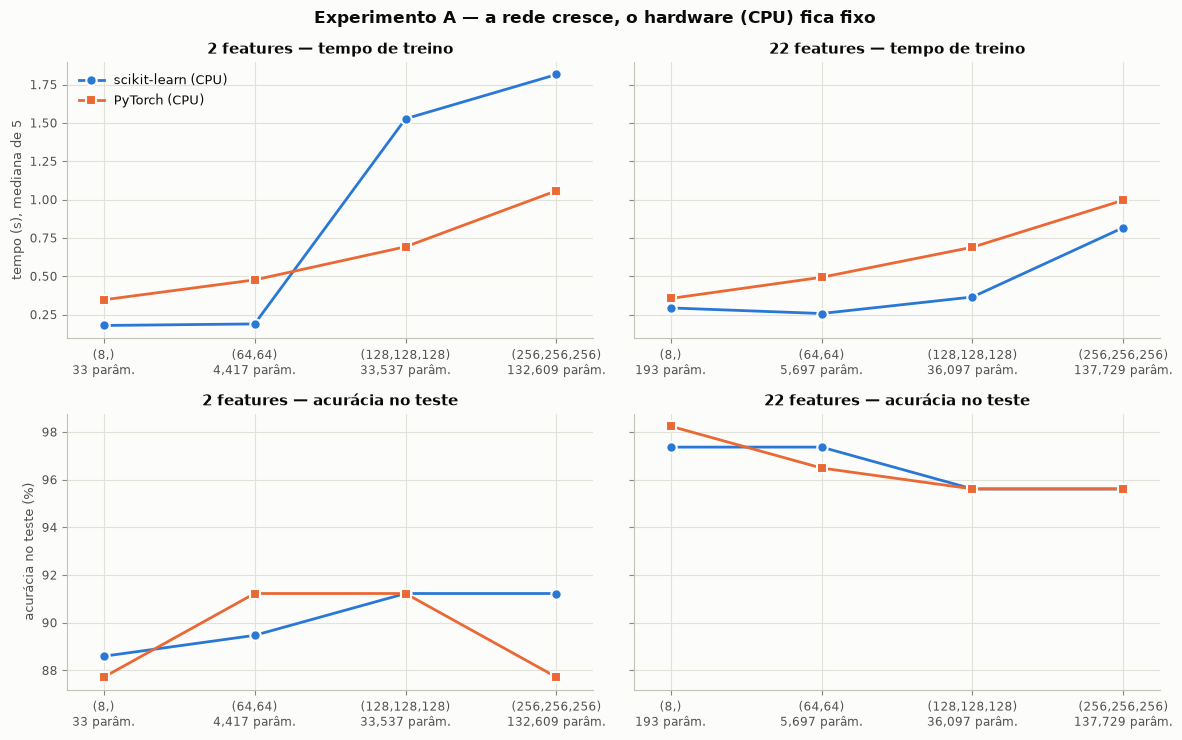

In [19]:
AZUL, LARANJA, AQUA = '#2a78d6', '#eb6834', '#1baf7a'
TINTA, TINTA_2, APAGADO, GRADE, EIXO, FUNDO = '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7', '#fcfcfb'
plt.rcParams.update({
    'figure.facecolor': FUNDO, 'axes.facecolor': FUNDO, 'savefig.facecolor': FUNDO,
    'axes.edgecolor': EIXO, 'axes.linewidth': 0.8, 'axes.grid': True, 'grid.color': GRADE, 'grid.linewidth': 0.8,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.axisbelow': True,
    'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.titlecolor': TINTA,
    'axes.labelsize': 9.5, 'axes.labelcolor': TINTA_2,
    'xtick.color': APAGADO, 'ytick.color': APAGADO, 'xtick.labelcolor': TINTA_2, 'ytick.labelcolor': TINTA_2,
    'xtick.labelsize': 8.5, 'ytick.labelsize': 8.5,
    'legend.frameon': False, 'legend.fontsize': 9, 'text.color': TINTA,
    'lines.linewidth': 2, 'lines.markersize': 7.5,
    'lines.markeredgecolor': FUNDO, 'lines.markeredgewidth': 1.5,
})
SERIES_FW = [('scikit-learn (CPU)', AZUL, 'o'), ('PyTorch (CPU)', LARANJA, 's')]
ENTRADAS = ['2 features', '22 features']


def salvar(fig, nome):
    fig.savefig(os.path.join(PASTA, 'figuras', nome), dpi=150, bbox_inches='tight')
    plt.show()


# ---------------- Figura 1: Experimento A ----------------
fig, eixos = plt.subplots(2, 2, figsize=(12, 7.5), sharey='row')
for j, entrada in enumerate(ENTRADAS):
    bloco = tabela_A[tabela_A['Entrada'] == entrada]
    for fw, cor, marcador in SERIES_FW:
        s = bloco[bloco['Framework'] == fw].reset_index(drop=True)
        eixos[0, j].plot(s.index, s['Tempo (s)'], marker=marcador, color=cor, label=fw)
        eixos[1, j].plot(s.index, 100 * s['Acurácia'], marker=marcador, color=cor, label=fw)
    for i in range(2):
        ax = eixos[i, j]
        ax.set_xticks(range(len(s)))
        ax.set_xticklabels([f'{a}\n{p:,} parâm.' for a, p in zip(s['Arquitetura'], s['Parâmetros'])])
        ax.margins(x=0.08)
    eixos[0, j].set_title(f'{entrada} — tempo de treino')
    eixos[1, j].set_title(f'{entrada} — acurácia no teste')
eixos[0, 0].set_ylabel('tempo (s), mediana de 5')
eixos[1, 0].set_ylabel('acurácia no teste (%)')
eixos[0, 0].legend(loc='upper left')
fig.suptitle('Experimento A — a rede cresce, o hardware (CPU) fica fixo', fontweight='bold', color=TINTA)
fig.tight_layout()
salvar(fig, 'fig1_experimento_A_escala_cpu.png')

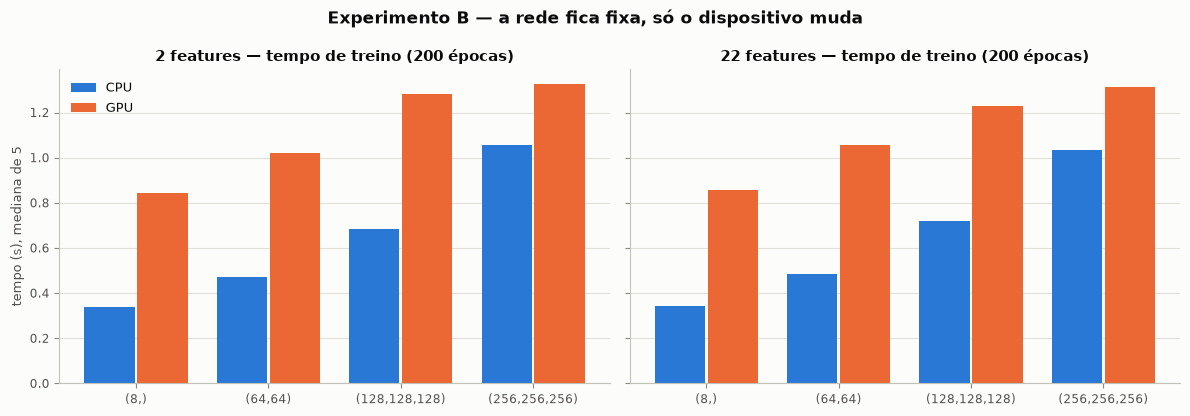

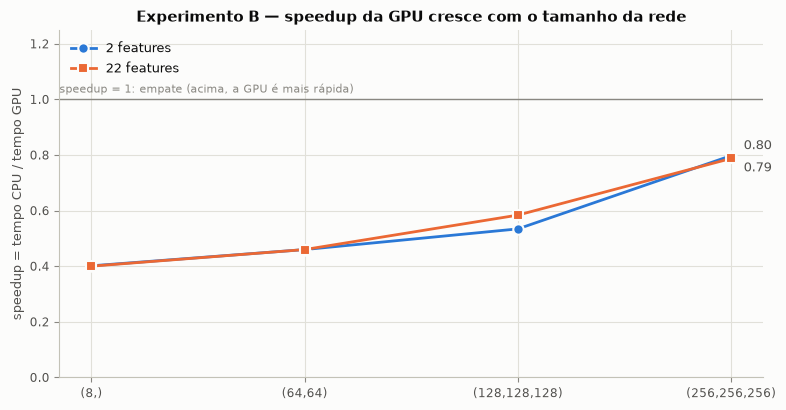

In [20]:
# ---------------- Figura 2: Experimento B — tempos ----------------
if GPU is not None:
    fig, eixos = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
    for ax, entrada in zip(eixos, ENTRADAS):
        s = tabela_B[tabela_B['Entrada'] == entrada]
        x = np.arange(len(s))
        largura = 0.38
        ax.bar(x - largura / 2 - 0.01, s['CPU (s)'], largura, color=AZUL, label='CPU')
        ax.bar(x + largura / 2 + 0.01, s['GPU (s)'], largura, color=LARANJA, label='GPU')
        ax.set_xticks(x)
        ax.set_xticklabels(s['Arquitetura'])
        ax.grid(axis='x', visible=False)
        ax.set_title(f'{entrada} — tempo de treino ({EPOCAS} épocas)')
    eixos[0].set_ylabel('tempo (s), mediana de 5')
    eixos[0].legend(loc='upper left')
    fig.suptitle('Experimento B — a rede fica fixa, só o dispositivo muda', fontweight='bold', color=TINTA)
    fig.tight_layout()
    salvar(fig, 'fig2_experimento_B_tempos_cpu_gpu.png')

    # ---------------- Figura 3: Experimento B — speedup ----------------
    fig, ax = plt.subplots(figsize=(8, 4.2))
    finais = {e: tabela_B[tabela_B['Entrada'] == e]['Speedup'].iloc[-1] for e in ENTRADAS}
    for (entrada, cor, marcador) in [('2 features', AZUL, 'o'), ('22 features', LARANJA, 's')]:
        s = tabela_B[tabela_B['Entrada'] == entrada].reset_index(drop=True)
        ax.plot(s.index, s['Speedup'], marker=marcador, color=cor, label=entrada)
        outro = finais['22 features' if entrada == '2 features' else '2 features']
        deslocamento = 0 if abs(finais[entrada] - outro) > 0.05 else (7 if finais[entrada] >= outro else -7)
        ax.annotate(f"{s['Speedup'].iloc[-1]:.2f}", (s.index[-1], s['Speedup'].iloc[-1]),
                    textcoords='offset points', xytext=(9, deslocamento), va='center', color=TINTA_2, fontsize=9)
    ax.axhline(1, color=APAGADO, linewidth=1)
    ax.text(-0.15, 1.015, 'speedup = 1: empate (acima, a GPU é mais rápida)', color=APAGADO, fontsize=8, va='bottom')
    ax.set_xticks(range(len(ARQUITETURAS)))
    ax.set_xticklabels([fmt_arq(a) for a in ARQUITETURAS])
    ax.set_ylim(0, max(1.25, tabela_B['Speedup'].max() * 1.15))
    ax.set_ylabel('speedup = tempo CPU / tempo GPU')
    ax.set_title('Experimento B — speedup da GPU cresce com o tamanho da rede')
    ax.legend(loc='upper left')
    fig.tight_layout()
    salvar(fig, 'fig3_experimento_B_speedup.png')
else:
    print('GPU indisponível: figuras de CPU × GPU não geradas.')

## 9. Evidências numéricas para as questões 1–8

Cada célula abaixo calcula, a partir das tabelas desta execução, os números usados nas respostas da seção 11.

In [21]:
def sub(df, **filtros):
    m = np.ones(len(df), dtype=bool)
    for coluna, valor in filtros.items():
        m &= (df[coluna] == valor).to_numpy()
    return df[m].reset_index(drop=True)


def evolucao(df):
    """Para cada arquitetura: variação de parâmetros, tempo e acurácia em relação à anterior e à menor (8,)."""
    out = df[['Arquitetura', 'Parâmetros', 'Tempo (s)', 'Iter./épocas', 'Acurácia']].copy()
    base = out.iloc[0]
    out['× parâm. vs anterior'] = (out['Parâmetros'] / out['Parâmetros'].shift()).round(2)
    out['× tempo vs anterior'] = (out['Tempo (s)'] / out['Tempo (s)'].shift()).round(2)
    out['Δ acur. vs anterior (p.p.)'] = (100 * out['Acurácia'].diff()).round(2)
    out['× parâm. vs (8,)'] = (out['Parâmetros'] / base['Parâmetros']).round(1)
    out['× tempo vs (8,)'] = (out['Tempo (s)'] / base['Tempo (s)']).round(2)
    out['Δ acur. vs (8,) (p.p.)'] = (100 * (out['Acurácia'] - base['Acurácia'])).round(2)
    # Pareto: nenhuma outra arquitetura é ao mesmo tempo mais rápida e pelo menos tão precisa
    out['Pareto (tempo × acurácia)'] = [
        not any((o['Tempo (s)'] <= r['Tempo (s)']) and (o['Acurácia'] >= r['Acurácia']) and
                ((o['Tempo (s)'] < r['Tempo (s)']) or (o['Acurácia'] > r['Acurácia']))
                for _, o in out.iterrows())
        for _, r in out.iterrows()]
    return out


print('Q1 e Q2 — 2 features (1 acerto a mais no teste = +0,88 p.p.)')
for fw, _, _ in SERIES_FW:
    print(f'\n>>> {fw}')
    display(formatar(evolucao(sub(tabela_A, Entrada='2 features', Framework=fw))))

Q1 e Q2 — 2 features (1 acerto a mais no teste = +0,88 p.p.)

>>> scikit-learn (CPU)


,Arquitetura,Parâmetros,Tempo (s),Iter./épocas,Acurácia,× parâm. vs anterior,× tempo vs anterior,Δ acur. vs anterior (p.p.),"× parâm. vs (8,)","× tempo vs (8,)","Δ acur. vs (8,) (p.p.)",Pareto (tempo × acurácia)
0,"(8,)",33,0.179,309,88.60%,NaN,NaN,NaN,1.0,1.00,0.00,True
1,"(64,64)","4,417",0.190,128,89.47%,133.85,1.06,0.88,133.8,1.06,0.88,True
2,"(128,128,128)","33,537",1.527,308,91.23%,7.59,8.06,1.75,1016.3,8.51,2.63,True
3,"(256,256,256)","132,609",1.816,135,91.23%,3.95,1.19,0.00,4018.5,10.12,2.63,False



>>> PyTorch (CPU)


,Arquitetura,Parâmetros,Tempo (s),Iter./épocas,Acurácia,× parâm. vs anterior,× tempo vs anterior,Δ acur. vs anterior (p.p.),"× parâm. vs (8,)","× tempo vs (8,)","Δ acur. vs (8,) (p.p.)",Pareto (tempo × acurácia)
0,"(8,)",33,0.347,200,87.72%,NaN,NaN,NaN,1.0,1.00,0.00,True
1,"(64,64)","4,417",0.477,200,91.23%,133.85,1.37,3.51,133.8,1.37,3.51,True
2,"(128,128,128)","33,537",0.693,200,91.23%,7.59,1.45,0.00,1016.3,2.00,3.51,False
3,"(256,256,256)","132,609",1.058,200,87.72%,3.95,1.53,-3.51,4018.5,3.05,0.00,False


In [22]:
print('Q2/Q6 — mesma análise com 22 features')
for fw, _, _ in SERIES_FW:
    print(f'\n>>> {fw}')
    display(formatar(evolucao(sub(tabela_A, Entrada='22 features', Framework=fw))))

Q2/Q6 — mesma análise com 22 features

>>> scikit-learn (CPU)


,Arquitetura,Parâmetros,Tempo (s),Iter./épocas,Acurácia,× parâm. vs anterior,× tempo vs anterior,Δ acur. vs anterior (p.p.),"× parâm. vs (8,)","× tempo vs (8,)","Δ acur. vs (8,) (p.p.)",Pareto (tempo × acurácia)
0,"(8,)",193,0.294,491,97.37%,NaN,NaN,NaN,1.0,1.00,0.00,False
1,"(64,64)","5,697",0.257,158,97.37%,29.52,0.88,0.00,29.5,0.88,0.00,True
2,"(128,128,128)","36,097",0.365,70,95.61%,6.34,1.42,-1.75,187.0,1.24,-1.75,False
3,"(256,256,256)","137,729",0.818,57,95.61%,3.82,2.24,0.00,713.6,2.78,-1.75,False



>>> PyTorch (CPU)


,Arquitetura,Parâmetros,Tempo (s),Iter./épocas,Acurácia,× parâm. vs anterior,× tempo vs anterior,Δ acur. vs anterior (p.p.),"× parâm. vs (8,)","× tempo vs (8,)","Δ acur. vs (8,) (p.p.)",Pareto (tempo × acurácia)
0,"(8,)",193,0.356,200,98.25%,NaN,NaN,NaN,1.0,1.00,0.00,True
1,"(64,64)","5,697",0.494,200,96.49%,29.52,1.39,-1.75,29.5,1.39,-1.75,False
2,"(128,128,128)","36,097",0.690,200,95.61%,6.34,1.40,-0.88,187.0,1.94,-2.63,False
3,"(256,256,256)","137,729",0.997,200,95.61%,3.82,1.44,0.00,713.6,2.80,-2.63,False


In [23]:
# Q3 e Q4 — 2 × 22 features e razão de parâmetros
print('Parâmetros de uma MLP = Σ (n_entrada × n_saída + n_saída) por camada; só a 1ª camada depende do nº de features.')
for arq in ARQUITETURAS:
    p2 = parametros_pytorch(criar_ann(2, arq))
    p22 = parametros_pytorch(criar_ann(22, arq))
    print(f'{fmt_arq(arq):>15}: {p2:>7,} -> {p22:>7,} parâmetros | razão {p22 / p2:6.3f} | '
          f'diferença {p22 - p2:>5,} = (22 - 2) × {arq[0]} pesos da 1ª camada')
formatar(comparacao_2x22)

Parâmetros de uma MLP = Σ (n_entrada × n_saída + n_saída) por camada; só a 1ª camada depende do nº de features.
           (8,):      33 ->     193 parâmetros | razão  5.848 | diferença   160 = (22 - 2) × 8 pesos da 1ª camada
        (64,64):   4,417 ->   5,697 parâmetros | razão  1.290 | diferença 1,280 = (22 - 2) × 64 pesos da 1ª camada
  (128,128,128):  33,537 ->  36,097 parâmetros | razão  1.076 | diferença 2,560 = (22 - 2) × 128 pesos da 1ª camada
  (256,256,256): 132,609 -> 137,729 parâmetros | razão  1.039 | diferença 5,120 = (22 - 2) × 256 pesos da 1ª camada


,Framework,Arquitetura,Parâm. 2f,Parâm. 22f,Razão parâm. 22f/2f,Tempo 2f (s),Tempo 22f (s),Razão tempo 22f/2f,Iter. 2f,Iter. 22f,Acurácia 2f,Acurácia 22f,Δ acurácia (p.p.)
0,scikit-learn (CPU),"(8,)",33,193,5.848,0.179,0.294,1.64,309,491,88.60%,97.37%,8.77
1,scikit-learn (CPU),"(64,64)",4417,5697,1.290,0.190,0.257,1.36,128,158,89.47%,97.37%,7.89
2,scikit-learn (CPU),"(128,128,128)",33537,36097,1.076,1.527,0.365,0.24,308,70,91.23%,95.61%,4.39
3,scikit-learn (CPU),"(256,256,256)",132609,137729,1.039,1.816,0.818,0.45,135,57,91.23%,95.61%,4.39
4,PyTorch (CPU),"(8,)",33,193,5.848,0.347,0.356,1.03,200,200,87.72%,98.25%,10.53
5,PyTorch (CPU),"(64,64)",4417,5697,1.290,0.477,0.494,1.04,200,200,91.23%,96.49%,5.26
6,PyTorch (CPU),"(128,128,128)",33537,36097,1.076,0.693,0.690,1.00,200,200,91.23%,95.61%,4.39
7,PyTorch (CPU),"(256,256,256)",132609,137729,1.039,1.058,0.997,0.94,200,200,87.72%,95.61%,7.89


In [24]:
# Q5 — linhas do treino PyTorch (forward, perda, backward, atualização)
fonte, primeira_linha = inspect.getsourcelines(treinar_ann_pytorch)
for deslocamento, texto in enumerate(fonte):
    if any(marca in texto for marca in ('zero_grad', '(1)', '(2)', '(3)', '(4)')):
        print(f'linha {deslocamento + 1:>2} de treinar_ann_pytorch | {texto.rstrip()}')

linha 21 de treinar_ann_pytorch |             otimizador.zero_grad()                        # zera os gradientes do passo anterior
linha 22 de treinar_ann_pytorch |             logits = modelo(X_train[lote])                # (1) FORWARD
linha 23 de treinar_ann_pytorch |             perda = criterio(logits, y_train[lote])       # (2) CÁLCULO DA PERDA
linha 24 de treinar_ann_pytorch |             perda.backward()                              # (3) BACKWARD
linha 25 de treinar_ann_pytorch |             otimizador.step()                             # (4) ATUALIZAÇÃO DOS PESOS


In [25]:
# Q7 e Q8 — CPU × GPU
if GPU is not None:
    melhor = tabela_B.loc[tabela_B['Speedup'].idxmax()]
    print(f"Q7: maior speedup = {melhor['Speedup']:.2f} em {melhor['Arquitetura']} com {melhor['Entrada']} "
          f"(CPU {melhor['CPU (s)']:.3f} s / GPU {melhor['GPU (s)']:.3f} s)")
    print('Q8: leitura das faixas de 5 repetições em cada configuração:', tabela_B['Leitura'].value_counts().to_dict())
    folga = tabela_B['GPU mín (s)'] - tabela_B['CPU máx (s)']
    mais_apertado = tabela_B.loc[folga.idxmin()]
    print(f"    caso mais apertado: {mais_apertado['Entrada']} {mais_apertado['Arquitetura']} — CPU máx. "
          f"{mais_apertado['CPU máx (s)']:.3f} s x GPU mín. {mais_apertado['GPU mín (s)']:.3f} s")
    display(formatar(tabela_B.loc[tabela_B['Leitura'] != 'GPU mais rápida', COLUNAS_TABELA_B + ['Leitura']]))
    for entrada in ENTRADAS:
        s = sub(tabela_B, Entrada=entrada)
        print(f"{entrada}: parâmetros x{s['Parâmetros'].iloc[-1] / s['Parâmetros'].iloc[0]:,.0f} da (8,) para a (256,256,256) | "
              f"tempo CPU x{s['CPU (s)'].iloc[-1] / s['CPU (s)'].iloc[0]:.2f} | tempo GPU x{s['GPU (s)'].iloc[-1] / s['GPU (s)'].iloc[0]:.2f}")
    print('acurácia idêntica em CPU e GPU em', int((tabela_B['Acurácia CPU'] == tabela_B['Acurácia GPU']).sum()),
          'de', len(tabela_B), 'configurações')

Q7: maior speedup = 0.80 em (256,256,256) com 2 features (CPU 1.057 s / GPU 1.325 s)
Q8: leitura das faixas de 5 repetições em cada configuração: {'CPU mais rápida': 8}
    caso mais apertado: 22 features (256,256,256) — CPU máx. 1.115 s x GPU mín. 1.269 s


,Entrada,Arquitetura,Parâmetros,CPU (s),GPU (s),Speedup,Acurácia GPU,Leitura
0,2 features,"(8,)",33,0.338,0.842,0.40,87.72%,CPU mais rápida
1,2 features,"(64,64)","4,417",0.470,1.023,0.46,91.23%,CPU mais rápida
2,2 features,"(128,128,128)","33,537",0.686,1.284,0.53,91.23%,CPU mais rápida
3,2 features,"(256,256,256)","132,609",1.057,1.325,0.80,87.72%,CPU mais rápida
4,22 features,"(8,)",193,0.342,0.855,0.40,98.25%,CPU mais rápida
5,22 features,"(64,64)","5,697",0.486,1.056,0.46,96.49%,CPU mais rápida
6,22 features,"(128,128,128)","36,097",0.717,1.228,0.58,95.61%,CPU mais rápida
7,22 features,"(256,256,256)","137,729",1.034,1.313,0.79,95.61%,CPU mais rápida


2 features: parâmetros x4,018 da (8,) para a (256,256,256) | tempo CPU x3.13 | tempo GPU x1.57
22 features: parâmetros x714 da (8,) para a (256,256,256) | tempo CPU x3.02 | tempo GPU x1.54
acurácia idêntica em CPU e GPU em 8 de 8 configurações


## 10. Análise complementar (além do mínimo pedido)

Três verificações que sustentam a interpretação, sem alterar as Tabelas A e B:

* **10.1 Robustez da acurácia** — o teste tem 114 exames, então 1 acerto vale 0,88 p.p. Repetimos o treino com 10 sementes
  (novo sorteio treino/teste e novos pesos iniciais) para ver se as diferenças entre arquiteturas se mantêm. É uma comparação
  **descritiva** (sem teste estatístico) e **condicionada à lista fixa de 22 features** da seção 2, que foi escolhida no treino
  do sorteio principal — parte dessas linhas cai no teste de outros sorteios, então esta análise não valida a seleção de features.
* **10.2 Quando a GPU passa a compensar** — mantendo a ANN e os dados (22 features), variamos só a quantidade de trabalho por
  passo: o tamanho do lote e a largura das camadas. Cada medição usa 50 épocas (mediana de 5) e o resultado é apresentado como
  **custo temporal por época** e speedup. Mede velocidade de treino, não acurácia nem tempo até atingir uma mesma qualidade.
  A configuração (256,256,256) com lote completo aparece nas duas tabelas: a diferença entre as duas medições dá uma ideia
  do ruído de medição perto de speedup ≈ 1.
* **10.3 Para onde vai o tempo de um passo na GPU** — com o `torch.profiler`, na mesma função de treino e com os mesmos dados
  (22 features, lote 200), contamos os **kernels CUDA por passo** e somamos as **durações desses kernels** (no stream padrão
  eles executam em sequência). O tempo de parede por passo vem de execuções **sem** profiler da mesma configuração, porque a
  instrumentação aumenta o tempo de parede.

In [26]:
# 10.1 Robustez: 10 sementes (sorteio treino/teste + pesos iniciais)
SEMENTES = list(range(10))
linhas = []
for entrada, X_ in [('2 features', dados_reduzidos[['radius_mean', 'texture_mean']]),
                    ('22 features', dados_reduzidos.drop(columns=['diagnosis']))]:
    for semente in SEMENTES:
        d = preparar_dados(X_, dados_reduzidos['diagnosis'], seed=semente)
        for arq in ARQUITETURAS:
            modelo, _, _ = treinar_sklearn(arq, d, seed=semente)
            linhas.append({'Entrada': entrada, 'Framework': 'scikit-learn (CPU)', 'Arquitetura': fmt_arq(arq),
                           'Semente': semente, 'Acurácia': accuracy_score(d['y_test'], modelo.predict(d['X_test']))})
            modelo, _ = treinar_ann_pytorch(arq, d, CPU, seed=semente)
            linhas.append({'Entrada': entrada, 'Framework': 'PyTorch (CPU)', 'Arquitetura': fmt_arq(arq),
                           'Semente': semente, 'Acurácia': acuracia_pytorch(modelo, d['X_test'], d['y_test'], CPU)})
robustez = pd.DataFrame(linhas)
robustez.to_csv(os.path.join(PASTA, 'complementar_robustez_sementes.csv'), index=False)
resumo_robustez = (robustez.groupby(['Entrada', 'Framework', 'Arquitetura'], sort=False)['Acurácia']
                   .agg(media='mean', desvio='std', minimo='min', maximo='max').reset_index())
resumo_robustez.to_csv(os.path.join(PASTA, 'complementar_robustez_resumo.csv'), index=False)
pd.DataFrame({'Entrada': resumo_robustez['Entrada'], 'Framework': resumo_robustez['Framework'],
              'Arquitetura': resumo_robustez['Arquitetura'],
              'Acurácia média ± desvio (%)': [f'{100 * m:.2f} ± {100 * s:.2f}'
                                              for m, s in zip(resumo_robustez['media'], resumo_robustez['desvio'])],
              'Mín (%)': (100 * resumo_robustez['minimo']).round(2),
              'Máx (%)': (100 * resumo_robustez['maximo']).round(2)})

,Entrada,Framework,Arquitetura,Acurácia média ± desvio (%),Mín (%),Máx (%)
0,2 features,scikit-learn (CPU),"(8,)",91.23 ± 2.48,87.72,95.61
1,2 features,PyTorch (CPU),"(8,)",90.70 ± 3.13,84.21,94.74
2,2 features,scikit-learn (CPU),"(64,64)",91.32 ± 2.09,87.72,93.86
3,2 features,PyTorch (CPU),"(64,64)",91.05 ± 1.79,87.72,93.86
4,2 features,scikit-learn (CPU),"(128,128,128)",90.26 ± 1.82,87.72,92.98
5,2 features,PyTorch (CPU),"(128,128,128)",90.88 ± 2.27,85.96,93.86
6,2 features,scikit-learn (CPU),"(256,256,256)",90.79 ± 2.16,86.84,93.86
7,2 features,PyTorch (CPU),"(256,256,256)",91.05 ± 1.97,87.72,94.74
8,22 features,scikit-learn (CPU),"(8,)",96.58 ± 1.13,93.86,97.37
9,22 features,PyTorch (CPU),"(8,)",95.96 ± 1.25,93.86,98.25


In [27]:
# 10.2 Quando a GPU passa a compensar (22 features)
EPOCAS_COMPL, REP_COMPL = 50, 5
if GPU is None:
    print('GPU indisponível: análise 10.2 não executada.')
else:
    n_treino = len(dados_22f['y_train'])
    linhas = []
    for batch in [32, BATCH_SIZE, n_treino]:          # n_treino = lote completo (1 passo por época)
        for arq in ARQUITETURAS:
            cpu = medir_pytorch(arq, dados_22f, CPU, REP_COMPL, EPOCAS_COMPL, batch)
            gpu = medir_pytorch(arq, dados_22f, GPU, REP_COMPL, EPOCAS_COMPL, batch)
            linhas.append({'Lote': batch, 'Arquitetura': fmt_arq(arq), 'Parâmetros': cpu['Parâmetros'],
                           'CPU (ms/época)': 1000 * cpu['Tempo (s)'] / EPOCAS_COMPL,
                           'GPU (ms/época)': 1000 * gpu['Tempo (s)'] / EPOCAS_COMPL,
                           'Speedup': cpu['Tempo (s)'] / gpu['Tempo (s)']})
    speedup_lote = pd.DataFrame(linhas)
    speedup_lote.to_csv(os.path.join(PASTA, 'complementar_speedup_por_lote.csv'), index=False)

    linhas = []
    for largura in [256, 512, 1024, 2048]:            # 3 camadas ocultas de mesma largura, lote completo
        arq = (largura,) * 3
        cpu = medir_pytorch(arq, dados_22f, CPU, REP_COMPL, EPOCAS_COMPL, n_treino)
        gpu = medir_pytorch(arq, dados_22f, GPU, REP_COMPL, EPOCAS_COMPL, n_treino)
        linhas.append({'Arquitetura': fmt_arq(arq), 'Parâmetros': cpu['Parâmetros'],
                       'CPU (ms/época)': 1000 * cpu['Tempo (s)'] / EPOCAS_COMPL,
                       'GPU (ms/época)': 1000 * gpu['Tempo (s)'] / EPOCAS_COMPL,
                       'Speedup': cpu['Tempo (s)'] / gpu['Tempo (s)']})
    speedup_largura = pd.DataFrame(linhas)
    speedup_largura.to_csv(os.path.join(PASTA, 'complementar_speedup_por_largura.csv'), index=False)

    print('Speedup por tamanho de lote (lote completo =', n_treino, 'amostras):')
    display(speedup_lote.pivot(index='Arquitetura', columns='Lote', values='Speedup')
            .loc[[fmt_arq(a) for a in ARQUITETURAS]].round(2))
    print('Speedup por largura das camadas (lote completo):')
    display(speedup_largura.round(2))

Speedup por tamanho de lote (lote completo = 455 amostras):


Lote,32,200,455
Arquitetura,,,
"(8,)",0.53,0.39,0.45
"(64,64)",0.45,0.47,0.61
"(128,128,128)",0.50,0.64,0.59
"(256,256,256)",0.65,0.78,1.43


Speedup por largura das camadas (lote completo):


,Arquitetura,Parâmetros,CPU (ms/época),GPU (ms/época),Speedup
0,"(256,256,256)",137729,2.26,2.41,0.94
1,"(512,512,512)",537601,5.82,2.61,2.23
2,"(1024,1024,1024)",2123777,19.18,2.67,7.18
3,"(2048,2048,2048)",8441857,76.97,6.35,12.12


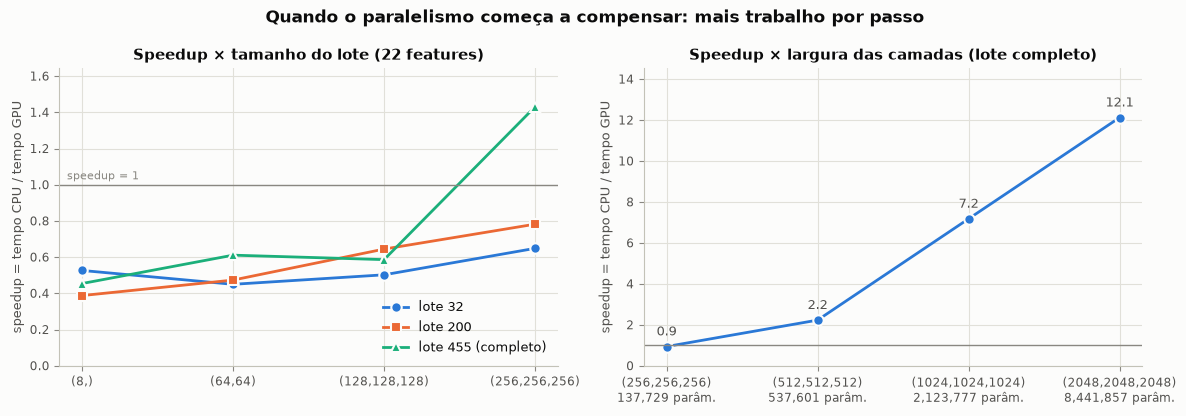

In [28]:
# Figura 4 — ponto de virada da GPU
if GPU is not None:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
    for (batch, cor, marcador) in zip(sorted(speedup_lote['Lote'].unique()), [AZUL, LARANJA, AQUA], ['o', 's', '^']):
        s = speedup_lote[speedup_lote['Lote'] == batch].reset_index(drop=True)
        rotulo = f'lote {batch}' + (' (completo)' if batch == len(dados_22f['y_train']) else '')
        ax1.plot(s.index, s['Speedup'], marker=marcador, color=cor, label=rotulo)
    ax1.set_xticks(range(len(ARQUITETURAS)))
    ax1.set_xticklabels([fmt_arq(a) for a in ARQUITETURAS])
    ax1.set_title('Speedup × tamanho do lote (22 features)')
    ax1.legend(loc='lower right')

    ax2.plot(range(len(speedup_largura)), speedup_largura['Speedup'], marker='o', color=AZUL)
    for i, v in enumerate(speedup_largura['Speedup']):
        ax2.annotate(f'{v:.1f}', (i, v), textcoords='offset points', xytext=(0, 8), ha='center', color=TINTA_2, fontsize=9)
    ax2.set_xticks(range(len(speedup_largura)))
    ax2.set_xticklabels([f"{a}\n{p:,} parâm." for a, p in zip(speedup_largura['Arquitetura'], speedup_largura['Parâmetros'])])
    ax2.set_title('Speedup × largura das camadas (lote completo)')
    for ax in (ax1, ax2):
        ax.axhline(1, color=APAGADO, linewidth=1)
        ax.set_ylabel('speedup = tempo CPU / tempo GPU')
    ax1.set_ylim(0, max(1.25, speedup_lote['Speedup'].max() * 1.15))
    ax1.text(-0.1, 1.015, 'speedup = 1', color=APAGADO, fontsize=8, ha='left', va='bottom')
    ax2.set_ylim(0, speedup_largura['Speedup'].max() * 1.2)
    fig.suptitle('Quando o paralelismo começa a compensar: mais trabalho por passo', fontweight='bold', color=TINTA)
    fig.tight_layout()
    salvar(fig, 'fig4_complementar_ponto_de_virada_gpu.png')

In [29]:
# 10.3 Para onde vai o tempo de um passo na GPU (torch.profiler; fora das medições das Tabelas A e B)
@contextlib.contextmanager
def stderr_em_arquivo(caminho):
    """O profiler escreve logs internos direto no descritor 2 (stderr): guardamos num arquivo para inspecionar depois."""
    sys.stderr.flush()
    copia = os.dup(2)
    with open(caminho, 'w') as destino:
        os.dup2(destino.fileno(), 2)
        try:
            yield
        finally:
            os.dup2(copia, 2)
            os.close(copia)


EPOCAS_PERFIL = 10
perfil_gpu = None
if GPU is None:
    print('GPU indisponível: 10.3 não executada.')
else:
    try:
        from torch.profiler import ProfilerActivity, profile
        passos_perfil = EPOCAS_PERFIL * math.ceil(len(dados_22f['y_train']) / BATCH_SIZE)
        pasta_tmp = tempfile.mkdtemp()
        log, trace = os.path.join(pasta_tmp, 'stderr.txt'), os.path.join(pasta_tmp, 'trace.json')
        linhas, diagnosticos = [], []
        for arq in ARQUITETURAS:
            treinar_ann_pytorch(arq, dados_22f, GPU, epocas=2)                                   # aquecimento
            with stderr_em_arquivo(log), profile(activities=[ProfilerActivity.CUDA]) as perfil:
                treinar_ann_pytorch(arq, dados_22f, GPU, epocas=EPOCAS_PERFIL)
            perfil.export_chrome_trace(trace)
            with open(trace, encoding='utf-8') as f:
                eventos = json.load(f)['traceEvents']
            # classificação explícita pela categoria que o próprio profiler atribui a cada evento da GPU
            contagem = {cat: [0, 0.0] for cat in ('kernel', 'gpu_memcpy', 'gpu_memset')}
            for ev in eventos:
                if ev.get('ph') == 'X' and ev.get('cat') in contagem:
                    contagem[ev['cat']][0] += 1
                    contagem[ev['cat']][1] += ev.get('dur', 0.0)                                   # microssegundos
            with open(log, encoding='utf-8', errors='replace') as f:
                diagnosticos += [l.strip() for l in f if l.strip() and not re.search(r'profiler_(start|stop)|Completed Stage', l)]
            # tempo de parede da MESMA configuração, medido sem profiler (a instrumentação o aumentaria)
            parede = [treinar_ann_pytorch(arq, dados_22f, GPU, epocas=EPOCAS_PERFIL)[1] for _ in range(REPETICOES)]
            linhas.append({'Arquitetura': fmt_arq(arq),
                           'Kernels por passo': contagem['kernel'][0] / passos_perfil,
                           'Soma das durações dos kernels (ms/passo)': contagem['kernel'][1] / 1000 / passos_perfil,
                           'Memcpy por passo': contagem['gpu_memcpy'][0] / passos_perfil,
                           'Memset por passo': contagem['gpu_memset'][0] / passos_perfil,
                           'Tempo de parede sem profiler (ms/passo)': 1000 * float(np.median(parede)) / passos_perfil})
        perfil_gpu = pd.DataFrame(linhas)
        perfil_gpu.to_csv(os.path.join(PASTA, 'complementar_perfil_gpu.csv'), index=False)
        print(f'22 features, lote {BATCH_SIZE}: {EPOCAS_PERFIL} épocas = {passos_perfil} passos. Valores por passo são totais '
              f'amortizados pelos {passos_perfil} passos (incluem a preparação de cada treino: cópias de modelo e dados).')
        print('diagnósticos do profiler:', 'nenhum além do início/fim da coleta' if not diagnosticos else '')
        for linha in diagnosticos:
            print('  ', linha)
        display(perfil_gpu.round(3))
    except Exception as erro:
        perfil_gpu = None
        print(f'profiler indisponível neste ambiente ({type(erro).__name__}: {erro}); 10.3 não executada.')

22 features, lote 200: 10 épocas = 30 passos. Valores por passo são totais amortizados pelos 30 passos (incluem a preparação de cada treino: cópias de modelo e dados).
diagnósticos do profiler: nenhum além do início/fim da coleta


,Arquitetura,Kernels por passo,Soma das durações dos kernels (ms/passo),Memcpy por passo,Memset por passo,Tempo de parede sem profiler (ms/passo)
0,"(8,)",31.267,0.062,0.533,0.000,1.790
1,"(64,64)",36.400,0.085,0.600,0.000,2.339
2,"(128,128,128)",43.867,0.125,0.667,0.667,2.737
3,"(256,256,256)",43.867,0.394,0.667,0.667,2.175


In [30]:
with open(os.path.join(PASTA, 'ambiente.json'), 'w', encoding='utf-8') as f:
    json.dump(AMBIENTE, f, ensure_ascii=False, indent=2)
print(json.dumps(AMBIENTE, ensure_ascii=False, indent=2))
print('arquivos em', PASTA, '->', sorted(os.listdir(PASTA)))

{
  "data_execucao": "2026-10-14 08:16",
  "sistema": "Windows 11 (build 26200)",
  "python": "3.11.9",
  "cpu": "11th Gen Intel(R) Core(TM) i7-11700K @ 3.60GHz",
  "nucleos_fisicos": 8,
  "nucleos_logicos": 16,
  "ram_gb": 31.9,
  "threads_pytorch_cpu": 8,
  "numpy": "2.4.6",
  "pandas": "3.0.6",
  "scikit-learn": "1.9.1",
  "torch": "2.14.1+cu130",
  "gpu_disponivel": true,
  "gpu": "NVIDIA GeForce RTX 3060",
  "gpu_memoria_gb": 12.0,
  "cuda": "13.0",
  "gpu_contexto_s": 0.029397300095297396,
  "gpu_primeiro_treino_frio_s": 1.4345589000731707
}
arquivos em resultados -> ['ambiente.json', 'comparacao_2_vs_22_features.csv', 'complementar_perfil_gpu.csv', 'complementar_robustez_resumo.csv', 'complementar_robustez_sementes.csv', 'complementar_speedup_por_largura.csv', 'complementar_speedup_por_lote.csv', 'figuras', 'selecao_features.json', 'tabela_A_escala_cpu.csv', 'tabela_B_cpu_gpu.csv']


## 11. Respostas às questões de análise
<!-- entrega:respostas -->

As respostas foram redigidas sobre a execução registrada neste arquivo. As duas células abaixo conferem, a cada execução: **(a)** se cada afirmação qualitativa das respostas continua válida e **(b)** se os números citados ainda são os desta execução (assinatura de todas as dependências do texto). Se aparecer ✘, o texto precisa ser revisto.

In [31]:
# 11.1 Funções de checagem das respostas.
# (a) Interpretação: cada afirmação qualitativa usada nas respostas é testada de novo sobre a execução corrente.
# (b) Números: a assinatura de TODAS as dependências brutas do texto (tabelas, robustez, análises complementares,
#     hardware, configuração e linhas da Q5) é comparada com a da execução sobre a qual as respostas foram redigidas.
import hashlib

SK, PT = 'scikit-learn (CPU)', 'PyTorch (CPU)'


def _bruto(valor):
    if valor is None or isinstance(valor, str):
        return valor
    if isinstance(valor, (bool, np.bool_)):
        return bool(valor)
    if isinstance(valor, (int, np.integer)):
        return int(valor)
    if isinstance(valor, (float, np.floating)):
        return None if math.isnan(valor) else round(float(valor), 9)
    return str(valor)


def _linhas(df):
    return None if df is None else [[_bruto(v) for v in linha] for linha in df.itertuples(index=False)]


def _camadas(texto_arquitetura):
    return [int(x) for x in texto_arquitetura.strip('()').split(',') if x]


def linhas_q5():
    fonte, _ = inspect.getsourcelines(treinar_ann_pytorch)
    return [[i + 1, t.strip()] for i, t in enumerate(fonte) if any(m in t for m in ('zero_grad', '(1)', '(2)', '(3)', '(4)'))]


def dependencias_das_respostas():
    """Todos os valores brutos dos quais o texto das respostas depende."""
    g = globals()
    return {
        'config': [EPOCAS, BATCH_SIZE, REPETICOES, LR, MAX_ITER_SKLEARN, SEED, TEST_SIZE,
                   len(dados_2f['y_train']), len(dados_2f['y_test'])],
        'ambiente': {k: _bruto(v) for k, v in AMBIENTE.items() if k != 'data_execucao'},
        'selecao': SELECAO,
        'tabela_A': _linhas(tabela_A),
        'tabela_B': _linhas(tabela_B),
        'robustez': _linhas(resumo_robustez),
        'speedup_lote': _linhas(g.get('speedup_lote')),
        'speedup_largura': _linhas(g.get('speedup_largura')),
        'perfil_gpu': _linhas(g.get('perfil_gpu')),
        'linhas_q5': linhas_q5(),
    }


def assinatura(dependencias):
    texto = json.dumps(dependencias, ensure_ascii=False, sort_keys=True)
    return hashlib.sha256(texto.encode('utf-8')).hexdigest()[:16]


def pareto(entrada, framework):
    """Arquiteturas não dominadas em (tempo, acurácia): nenhuma outra é mais rápida e pelo menos tão precisa."""
    s = tabela_A[(tabela_A['Entrada'] == entrada) & (tabela_A['Framework'] == framework)]
    def dominada(r):
        return any(o['Tempo (s)'] <= r['Tempo (s)'] and o['Acurácia'] >= r['Acurácia'] and
                   (o['Tempo (s)'] < r['Tempo (s)'] or o['Acurácia'] > r['Acurácia']) for _, o in s.iterrows())
    return [r['Arquitetura'] for _, r in s.iterrows() if not dominada(r)]


def leitura_256_lote_completo():
    """(256,256,256) com lote completo, medida nas duas tabelas da 10.2: de que lado de 1 ficam as duas medições."""
    g = globals()
    L, G = g.get('speedup_lote'), g.get('speedup_largura')
    if L is None or G is None:
        return None
    a = round(float(L[(L['Arquitetura'] == '(256,256,256)') & (L['Lote'] == L['Lote'].max())]['Speedup'].iloc[0]), 2)
    b = round(float(G[G['Arquitetura'] == '(256,256,256)']['Speedup'].iloc[0]), 2)   # precisão exibida no texto
    if a > 1 and b > 1:
        return 'GPU à frente por pouco'
    if a < 1 and b < 1:
        return 'CPU à frente por pouco'
    return 'empate'


def conjuntos_citados():
    """Conjuntos, escolhas e leituras que o texto das respostas cita literalmente."""
    return {'pareto_2f_scikit-learn': pareto('2 features', SK), 'pareto_2f_PyTorch': pareto('2 features', PT),
            'linhas_q5': linhas_q5(), 'leituras_tabela_B': tabela_B['Leitura'].tolist(),
            'leitura_256_lote_completo': leitura_256_lote_completo()}


def checagens_das_respostas(esperado):
    A, B, R = tabela_A, tabela_B, resumo_robustez
    g = globals()
    L, G, P = g.get('speedup_lote'), g.get('speedup_largura'), g.get('perfil_gpu')
    arqs = [fmt_arq(x) for x in ARQUITETURAS]
    e2, e22 = '2 features', '22 features'

    def v(e, fw, arq, col='Acurácia'):
        return A[(A['Entrada'] == e) & (A['Framework'] == fw) & (A['Arquitetura'] == arq)][col].iloc[0]

    def media(e, fw, arq):
        return R[(R['Entrada'] == e) & (R['Framework'] == fw) & (R['Arquitetura'] == arq)]['media'].iloc[0]

    def b(e, arq, col):
        return B[(B['Entrada'] == e) & (B['Arquitetura'] == arq)][col].iloc[0]

    resultado = []

    def teste(rotulo, afirmacao, condicao):
        try:
            ok = bool(condicao())
        except Exception as erro:                       # ex.: GPU ou análise complementar indisponível
            ok, afirmacao = False, f'{afirmacao} [não verificável: {type(erro).__name__}]'
        resultado.append((rotulo, afirmacao, ok))

    teste('Q1', 'PyTorch/2f: a (64,64) tem a maior acurácia, e a (128,128,128) empata com ela gastando mais tempo',
          lambda: v(e2, PT, '(64,64)') == max(v(e2, PT, a) for a in arqs) == v(e2, PT, '(128,128,128)')
          and v(e2, PT, '(128,128,128)', 'Tempo (s)') > v(e2, PT, '(64,64)', 'Tempo (s)'))
    teste('Q1', 'PyTorch/2f: a (256,256,256) é mais lenta que a (128,128,128) e menos precisa que a (64,64); '
                'a (64,64) é mais precisa que a (8,)',
          lambda: v(e2, PT, '(256,256,256)', 'Tempo (s)') > v(e2, PT, '(128,128,128)', 'Tempo (s)')
          and v(e2, PT, '(256,256,256)') < v(e2, PT, '(64,64)') and v(e2, PT, '(64,64)') > v(e2, PT, '(8,)'))
    teste('Q1', 'scikit-learn/2f: a (64,64) leva menos de 1,3× o tempo da (8,); a (128,128,128) e a (256,256,256) '
                'acertam mais e levam mais de 5× o tempo da (64,64)',
          lambda: v(e2, SK, '(64,64)', 'Tempo (s)') < 1.3 * v(e2, SK, '(8,)', 'Tempo (s)')
          and min(v(e2, SK, a) for a in ('(128,128,128)', '(256,256,256)')) > v(e2, SK, '(64,64)')
          and min(v(e2, SK, a, 'Tempo (s)') for a in ('(128,128,128)', '(256,256,256)')) > 5 * v(e2, SK, '(64,64)', 'Tempo (s)'))
    teste('Q1', f"fronteiras de Pareto com 2 features iguais às citadas: scikit-learn {esperado['pareto_2f_scikit-learn']}, "
                f"PyTorch {esperado['pareto_2f_PyTorch']}",
          lambda: pareto(e2, SK) == esperado['pareto_2f_scikit-learn'] and pareto(e2, PT) == esperado['pareto_2f_PyTorch'])
    teste('Q1', 'robustez/2f: a (64,64) tem a maior média no scikit-learn e empata com a maior no PyTorch; '
                'a (128,128,128) fica abaixo dela no scikit-learn',
          lambda: media(e2, SK, '(64,64)') == max(media(e2, SK, a) for a in arqs)
          and abs(media(e2, PT, '(64,64)') - max(media(e2, PT, a) for a in arqs)) < 1e-12
          and media(e2, SK, '(128,128,128)') < media(e2, SK, '(64,64)'))
    teste('Q2', '(256,256,256): mesma acurácia da (128,128,128) no scikit-learn/2f; abaixo da (128,128,128) e igual à (8,) '
                'no PyTorch/2f; abaixo da (8,) com 22 features nos dois frameworks',
          lambda: v(e2, SK, '(256,256,256)') == v(e2, SK, '(128,128,128)')
          and v(e2, PT, '(256,256,256)') < v(e2, PT, '(128,128,128)') and v(e2, PT, '(256,256,256)') == v(e2, PT, '(8,)')
          and all(v(e22, fw, '(256,256,256)') < v(e22, fw, '(8,)') for fw in (SK, PT)))
    teste('Q3', 'a acurácia sobe de 2 para 22 features nas 8 combinações',
          lambda: all(v(e22, fw, a) > v(e2, fw, a) for fw in (SK, PT) for a in arqs))
    teste('Q3', 'PyTorch: o tempo com 22 features fica entre 0,8× e 1,25× o tempo com 2 features em todas as arquiteturas',
          lambda: all(0.8 < v(e22, PT, a, 'Tempo (s)') / v(e2, PT, a, 'Tempo (s)') < 1.25 for a in arqs))
    teste('Q3', 'scikit-learn: com 22 features a (8,) usa mais épocas e mais tempo; a (128,128,128) e a (256,256,256), '
                'menos épocas e menos tempo',
          lambda: v(e22, SK, '(8,)', 'Iter./épocas') > v(e2, SK, '(8,)', 'Iter./épocas')
          and v(e22, SK, '(8,)', 'Tempo (s)') > v(e2, SK, '(8,)', 'Tempo (s)')
          and all(v(e22, SK, a, 'Iter./épocas') < v(e2, SK, a, 'Iter./épocas') and v(e22, SK, a, 'Tempo (s)') < v(e2, SK, a, 'Tempo (s)')
                  for a in ('(128,128,128)', '(256,256,256)')))
    teste('Q4', 'parâmetros da Tabela A = Σ (n_entrada × n_saída + n_saída) em todas as linhas',
          lambda: all(r['Parâmetros'] == sum(i * o + o for i, o in zip([2 if r['Entrada'] == e2 else 22, *_camadas(r['Arquitetura'])],
                                                                      [*_camadas(r['Arquitetura']), 1]))
                      for _, r in A.iterrows()))
    teste('Q5', f"linhas do treino citadas na Q5 continuam as mesmas ({', '.join(str(n) for n, _ in esperado['linhas_q5'])})",
          lambda: linhas_q5() == esperado['linhas_q5'])
    teste('Q6', '22 features: no scikit-learn a (8,) empata com a (64,64) e supera a (256,256,256); no PyTorch a (8,) '
                'tem a maior acurácia',
          lambda: v(e22, SK, '(8,)') == v(e22, SK, '(64,64)') > v(e22, SK, '(256,256,256)')
          and v(e22, PT, '(8,)') == max(v(e22, PT, a) for a in arqs))
    teste('Q6', '22 features: acurácia de treino de 100% da (64,64) em diante nos dois frameworks',
          lambda: all(v(e22, fw, a, 'Acurácia treino') == 1.0 for fw in (SK, PT) for a in arqs[1:]))
    teste('Q6', 'robustez/22 features: as médias das quatro arquiteturas ficam a menos de 1,5 p.p. umas das outras',
          lambda: R[R['Entrada'] == e22]['media'].max() - R[R['Entrada'] == e22]['media'].min() < 0.015)
    teste('Q7', 'maior speedup na (256,256,256); speedup abaixo de 1 em todas as configurações e crescente com a arquitetura',
          lambda: B.loc[B['Speedup'].idxmax(), 'Arquitetura'] == '(256,256,256)' and (B['Speedup'].round(2) < 1).all()
          and all(B[B['Entrada'] == e]['Speedup'].is_monotonic_increasing for e in (e2, e22)))
    teste('Q8', 'nas redes pequenas, (8,) e (64,64), a CPU foi mais rápida em todas as repetições, nas duas entradas',
          lambda: all(b(e, a, 'Leitura') == 'CPU mais rápida' for e in (e2, e22) for a in ('(8,)', '(64,64)')))
    teste('Q8', f"leitura das faixas de repetições da Tabela B igual à citada ({sum(x == 'CPU mais rápida' for x in esperado['leituras_tabela_B'])} "
                f"de {len(esperado['leituras_tabela_B'])} configurações com a CPU mais rápida em todas as repetições)",
          lambda: B['Leitura'].tolist() == esperado['leituras_tabela_B'])
    teste('Q8', 'da (8,) para a (256,256,256), o tempo da GPU cresce menos que o da CPU, nas duas entradas',
          lambda: all(b(e, '(256,256,256)', 'GPU (s)') / b(e, '(8,)', 'GPU (s)') < b(e, '(256,256,256)', 'CPU (s)') / b(e, '(8,)', 'CPU (s)')
                      for e in (e2, e22)))
    teste('Q8', '10.2: na (256,256,256) o lote completo dá o maior speedup entre os lotes; na (8,) o speedup fica abaixo de 0,6 '
                'em todos os lotes',
          lambda: L[(L['Arquitetura'] == '(256,256,256)') & (L['Lote'] == L['Lote'].max())]['Speedup'].iloc[0]
          == L[L['Arquitetura'] == '(256,256,256)']['Speedup'].max()
          and (L[L['Arquitetura'] == '(8,)']['Speedup'] < 0.6).all())
    teste('Q8', f"10.2: a (256,256,256) com lote completo fica entre 0,8 e 1,5 nas duas tabelas, com a leitura citada "
                f"(\"{esperado['leitura_256_lote_completo']}\")",
          lambda: 0.8 < L[(L['Arquitetura'] == '(256,256,256)') & (L['Lote'] == L['Lote'].max())]['Speedup'].iloc[0] < 1.5
          and 0.8 < G[G['Arquitetura'] == '(256,256,256)']['Speedup'].iloc[0] < 1.5
          and leitura_256_lote_completo() == esperado['leitura_256_lote_completo'])
    teste('Q8', '10.2: o speedup cresce com a largura, passa de 1,5 a partir de 512 neurônios e de 10 na (2048,2048,2048); '
                'da (256,256,256) para a (1024,1024,1024) o custo da GPU por época sobe menos de 1,6× e o da CPU mais de 4×',
          lambda: G['Speedup'].is_monotonic_increasing and (G['Speedup'].iloc[1:] > 1.5).all() and G['Speedup'].iloc[-1] > 10
          and G[G['Arquitetura'] == '(1024,1024,1024)']['GPU (ms/época)'].iloc[0] < 1.6 * G[G['Arquitetura'] == '(256,256,256)']['GPU (ms/época)'].iloc[0]
          and G[G['Arquitetura'] == '(1024,1024,1024)']['CPU (ms/época)'].iloc[0] > 4 * G[G['Arquitetura'] == '(256,256,256)']['CPU (ms/época)'].iloc[0])
    teste('Q8', 'o 1º treino da GPU, ainda frio, demorou mais que a mediana aquecida da mesma configuração',
          lambda: AMBIENTE['gpu_primeiro_treino_frio_s'] > b('2 features', '(8,)', 'GPU (s)'))
    teste('Q8', '10.3: dezenas de kernels por passo; na (8,) e na (64,64) a soma das durações dos kernels fica abaixo de 1/10 '
                'do tempo de parede do passo; a soma cresce da (8,) para a (256,256,256)',
          lambda: P['Kernels por passo'].between(20, 99).all()
          and all(P[P['Arquitetura'] == a]['Soma das durações dos kernels (ms/passo)'].iloc[0]
                  < 0.1 * P[P['Arquitetura'] == a]['Tempo de parede sem profiler (ms/passo)'].iloc[0] for a in ('(8,)', '(64,64)'))
          and P[P['Arquitetura'] == '(8,)']['Soma das durações dos kernels (ms/passo)'].iloc[0]
          < P[P['Arquitetura'] == '(256,256,256)']['Soma das durações dos kernels (ms/passo)'].iloc[0])
    teste('Conclusão', 'com 22 features a (256,256,256) não acerta mais que a (8,) nem que a (64,64), em nenhum framework',
          lambda: max(v(e22, fw, '(256,256,256)') for fw in (SK, PT)) <= min(v(e22, fw, a) for fw in (SK, PT) for a in ('(8,)', '(64,64)')))
    return resultado


def relatorio_checagem(referencia):
    checagens = checagens_das_respostas(referencia['conjuntos'])
    atual = assinatura(dependencias_das_respostas())
    validas = sum(ok for _, _, ok in checagens)
    print(f'(a) Interpretação — {validas} de {len(checagens)} afirmações das respostas continuam válidas nesta execução:')
    for rotulo, afirmacao, ok in checagens:
        print(f"   {'✔' if ok else '✘'} {rotulo}: {afirmacao}")
    print(f"(b) Números — assinatura das dependências das respostas: registrada {referencia['assinatura']} "
          f"(execução de {referencia['execucao']}) | desta execução {atual}")
    if atual == referencia['assinatura']:
        print('   ✔ os números citados nas respostas são os desta execução')
    else:
        print('   ✘ esta execução produziu números diferentes dos citados: as respostas precisam ser atualizadas')
    return validas == len(checagens) and atual == referencia['assinatura']

In [32]:
# 11.2 Checagem: as respostas abaixo continuam valendo para esta execução?
# REFERENCIA = execução sobre a qual o texto foi redigido (fica congelada; não reexecutar para "atualizar").
REFERENCIA = {'assinatura': 'f75e366e0320acdf',
 'execucao': '2026-10-14 08:16',
 'conjuntos': {'pareto_2f_scikit-learn': ['(8,)', '(64,64)', '(128,128,128)'],
               'pareto_2f_PyTorch': ['(8,)', '(64,64)'],
               'linhas_q5': [[21,
                              'otimizador.zero_grad()                        # zera os gradientes do passo '
                              'anterior'],
                             [22, 'logits = modelo(X_train[lote])                # (1) FORWARD'],
                             [23, 'perda = criterio(logits, y_train[lote])       # (2) CÁLCULO DA PERDA'],
                             [24, 'perda.backward()                              # (3) BACKWARD'],
                             [25,
                              'otimizador.step()                             # (4) ATUALIZAÇÃO DOS PESOS']],
               'leituras_tabela_B': ['CPU mais rápida',
                                     'CPU mais rápida',
                                     'CPU mais rápida',
                                     'CPU mais rápida',
                                     'CPU mais rápida',
                                     'CPU mais rápida',
                                     'CPU mais rápida',
                                     'CPU mais rápida'],
               'leitura_256_lote_completo': 'empate'}}
respostas_conferem = relatorio_checagem(REFERENCIA)

(a) Interpretação — 24 de 24 afirmações das respostas continuam válidas nesta execução:
   ✔ Q1: PyTorch/2f: a (64,64) tem a maior acurácia, e a (128,128,128) empata com ela gastando mais tempo
   ✔ Q1: PyTorch/2f: a (256,256,256) é mais lenta que a (128,128,128) e menos precisa que a (64,64); a (64,64) é mais precisa que a (8,)
   ✔ Q1: scikit-learn/2f: a (64,64) leva menos de 1,3× o tempo da (8,); a (128,128,128) e a (256,256,256) acertam mais e levam mais de 5× o tempo da (64,64)
   ✔ Q1: fronteiras de Pareto com 2 features iguais às citadas: scikit-learn ['(8,)', '(64,64)', '(128,128,128)'], PyTorch ['(8,)', '(64,64)']
   ✔ Q1: robustez/2f: a (64,64) tem a maior média no scikit-learn e empata com a maior no PyTorch; a (128,128,128) fica abaixo dela no scikit-learn
   ✔ Q2: (256,256,256): mesma acurácia da (128,128,128) no scikit-learn/2f; abaixo da (128,128,128) e igual à (8,) no PyTorch/2f; abaixo da (8,) com 22 features nos dois frameworks
   ✔ Q3: a acurácia sobe de 2 para 22 fe

<!-- entrega:respostas -->

> Respostas redigidas sobre a execução registrada em 2026-10-14 08:16 (assinatura das dependências: f75e366e0320acdf). Todos os números vêm dessa execução — Tabelas A e B e seções 9 e 10. O teste tem 114 exames: 1 acerto equivale a 0,88 p.p.

### 1. No seu run com 2 features, qual arquitetura apresentou a melhor relação entre tempo e acurácia?

**Resposta: a (64,64), nos dois frameworks — como melhor compromisso entre tempo e acurácia.**

Critério: primeiro a fronteira de Pareto (arquiteturas para as quais nenhuma outra é ao mesmo tempo mais rápida e pelo menos tão precisa) — scikit-learn: (8,), (64,64) e (128,128,128); PyTorch: (8,) e (64,64). Dentro dela, a (64,64) é o melhor compromisso:

- **PyTorch:** a (64,64) atinge 91,23% em 0,477 s — a maior acurácia do PyTorch com 2 features. A (128,128,128) empata nessa acurácia gastando 0,693 s (+45% de tempo, 7,6× os parâmetros), e a (256,256,256) leva 1,058 s para cair a 87,72%. Em relação à (8,) (0,347 s; 87,72%), a (64,64) ganha +3,51 p.p. (4 acertos a mais) com +37% de tempo.
- **scikit-learn:** a (64,64) fica em 89,47% com 0,190 s, quase o tempo da (8,) (0,179 s; 88,60%). Para ganhar mais 1,75 p.p. (2 acertos), é preciso ir à (128,128,128) (1,527 s) ou à (256,256,256) (1,816 s): 8,1× e 9,6× o tempo da (64,64). Escolher a (64,64) aqui é um compromisso: abre mão desses 2 acertos em troca de um treino 8,1 vezes mais rápido.
- **Robustez (seção 10.1):** em 10 sorteios de treino/teste, a (64,64) tem a maior média do scikit-learn (91,32% ± 2,09 p.p.) e empata com a maior média do PyTorch (91,05% ± 1,79 p.p.); a vantagem pontual da (128,128,128) no scikit-learn não se repete na média (90,26% ± 1,82 p.p.).

### 2. Qual arquitetura teve o maior aumento de parâmetros sem produzir ganho proporcional de acurácia?

**Resposta: a (256,256,256).** Com 2 features ela tem 132.609 parâmetros — 4.018× os da (8,) (+132.576) e 3,95× os da (128,128,128) (+99.072). Em troca:

- **scikit-learn:** a mesma acurácia da (128,128,128) (91,23% → 91,23%, 0,00 p.p.) e só +2,63 p.p. sobre a (8,), com 10,1× o tempo da (8,) (1,816 s × 0,179 s).
- **PyTorch:** a acurácia **cai** de 91,23% na (128,128,128) para 87,72% (−3,51 p.p.) — o mesmo nível da (8,) —, com 3,05× o tempo da (8,).
- **Com 22 features** o padrão se repete: 714× os parâmetros da (8,) e −1,75 p.p. (scikit-learn) / −2,63 p.p. (PyTorch) de acurácia.

### 3. Ao passar de 2 para 22 features, o que mudou em tempo e acurácia?

- **Acurácia — subiu nas 8 combinações**, de +4,39 p.p. a +10,53 p.p. (exemplos: (8,) no PyTorch 87,72% → 98,25% (+10,53 p.p.); (8,) no scikit-learn 88,60% → 97,37% (+8,77 p.p.); (256,256,256) no scikit-learn 91,23% → 95,61% (+4,39 p.p.) e no PyTorch 87,72% → 95,61% (+7,89 p.p.)). As 20 medidas extras (concavidade, pontos côncavos, textura e suavidade no pior caso etc.) carregam muito mais informação sobre o tumor do que só o raio e a textura médios.
- **Tempo no PyTorch (200 épocas fixas) — praticamente não mudou** (variação de no máximo 6% entre as quatro arquiteturas): (8,) 0,347 s → 0,356 s (1,03×); (256,256,256) 1,058 s → 0,997 s (0,94×). Só a 1ª camada cresce (+3,9% de parâmetros na (256,256,256)), e nesse tamanho o tempo de cada passo pouco depende do número de entradas.
- **Tempo no scikit-learn (até atingir o critério de parada) — mudou pelo número de épocas:** a (8,) precisou de 491 épocas em vez de 309 e ficou mais lenta (0,179 s → 0,294 s); a (128,128,128) parou em 70 épocas em vez de 308 (1,527 s → 0,365 s, 4,2× mais rápida) e a (256,256,256) em 57 em vez de 135 (1,816 s → 0,818 s). Com 22 features, as redes maiores chegam antes ao platô da perda de treino que o critério de parada detecta — e todas, da (64,64) em diante, atingem 100% de acurácia no treino.

### 4. Razão entre o número de parâmetros com 22 e com 2 features — e de onde vem a diferença

**(8,):** 193 / 33 = **5,85**. **(256,256,256):** 137.729 / 132.609 = **1,039**.

Cada camada densa tem `n_entrada × n_saída` pesos + `n_saída` vieses, e só a 1ª camada depende do número de features. Passar de 2 para 22 features acrescenta (22 − 2) × n₁ pesos: 20 × 8 = 160 na (8,) — muito diante dos 33 parâmetros originais — e 20 × 256 = 5.120 na (256,256,256), pouco diante dos 131.072 pesos das duas camadas 256 × 256, que não dependem da entrada. Por isso a razão é grande nas redes pequenas e tende a 1 nas grandes.

### 5. Linhas que executam forward, cálculo da perda, backward e atualização dos pesos (PyTorch)

Na função `treinar_ann_pytorch` (seção 3 do notebook; a célula da seção 9 imprime as linhas com a numeração):

- linha 21: `otimizador.zero_grad()` — zera os gradientes acumulados no passo anterior;
- linha 22: `logits = modelo(X_train[lote])` — **forward** (a rede calcula os logits do lote);
- linha 23: `perda = criterio(logits, y_train[lote])` — **cálculo da perda** (`BCEWithLogitsLoss`);
- linha 24: `perda.backward()` — **backward** (retropropagação: gradiente da perda em relação a cada peso);
- linha 25: `otimizador.step()` — **atualização dos pesos** (passo do Adam).

Esse bloco roda uma vez por lote: 3 lotes × 200 épocas = 600 passos de otimização por treino.

### 6. Os resultados permitem afirmar que uma rede maior é automaticamente melhor?

**Não.** Cinco resultados desta execução contradizem a ideia:

- **22 features, scikit-learn:** a (8,) — 193 parâmetros, 0,294 s — acerta 97,37%, o mesmo que a (64,64) e mais que a (256,256,256) (137.729 parâmetros, 0,818 s), que fica em 95,61%.
- **22 features, PyTorch:** a (8,) tem a maior acurácia (98,25%); a (256,256,256) usa 714× mais parâmetros e 2,80× mais tempo para chegar a 95,61%.
- **2 features, PyTorch:** (256,256,256) = (8,) = 87,72%, abaixo da (64,64) (91,23%).
- **Sinal compatível com sobreajuste:** com 22 features, todas as redes a partir da (64,64) chegam a 100% de acurácia no treino, mas não passam de 97,37% no teste — a capacidade extra não se converteu em generalização.
- **Robustez (seção 10.1, comparação descritiva):** em 10 sorteios, as médias das quatro arquiteturas com 22 features ficam entre 95,96% e 96,75%, com desvio-padrão de 1,1 a 1,8 p.p. — a diferença entre arquiteturas é menor que a variação causada pelo próprio sorteio.

Aumentar a rede **não melhorou sistematicamente** a acurácia: houve ganhos pontuais (por exemplo, +3,51 p.p. da (8,) para a (64,64) no PyTorch com 2 features), mas nenhum que acompanhe o crescimento dos parâmetros. O que melhorou o resultado de forma consistente foi a informação de entrada (2 → 22 features: +4,39 p.p. a +10,53 p.p.).

### 7. Em qual arquitetura apareceu o maior speedup?

**Na (256,256,256).** Com 2 features: tempo_CPU = 1,057 s, tempo_GPU = 1,325 s, speedup = 1,057 / 1,325 = **0,80**. Com 22 features: 1,034 s / 1,313 s = **0,79**.

Mesmo no melhor caso o speedup ficou abaixo de 1 — a GPU levou cerca de 1,3× o tempo da CPU —, mas ele cresce a cada aumento da rede: 0,40 → 0,46 → 0,53 → 0,80 (2 features) e 0,40 → 0,46 → 0,58 → 0,79 (22 features).

### 8. Alguma arquitetura pequena foi tão rápida ou mais rápida na CPU?

**Sim — e não só as pequenas: a CPU foi mais rápida nas 8 configurações.** O critério é o das repetições: em cada configuração, até a execução mais lenta da CPU foi mais rápida que a execução mais rápida da GPU (caso mais apertado: 22 features (256,256,256), 1,115 s × 1,269 s). Na (8,) a CPU foi 2,5× mais rápida com 2 features (0,338 s × 0,842 s, speedup 0,40) e 2,5× com 22 features (0,342 s × 0,855 s, speedup 0,40).

Explicação compatível com os dados — o overhead da GPU domina quando há pouco cálculo por passo:

- **Muitas operações pequenas por passo (seção 10.3, `torch.profiler`, 22 features, lote 200):** cada passo de treino dispara, em média, 31 kernels CUDA na (8,) e 44 na (256,256,256) (forward, perda, backward e Adam). Na (8,), as durações desses kernels somam 0,062 ms por passo, para um passo de 1,79 ms de parede na mesma configuração (medido sem profiler); na (64,64), 0,085 ms para 2,34 ms. (Esse passo é mais lento que o da Tabela B porque aqui a preparação de cada treino se dilui em só 30 passos, e não em 600.) Nas redes pequenas, o cálculo na GPU é uma parte pequena do passo; o restante vai para lançar kernels, sincronizar e coordenar a partir da CPU — na (8,), a multiplicação é de uma matriz 200 × 22 por outra 22 × 8, pouco trabalho para os milhares de núcleos da GPU. Na (256,256,256) a soma sobe para 0,394 ms (para 2,18 ms de parede): há mais cálculo por passo, e é também onde o speedup é maior.
- **O tempo da GPU quase não acompanha o tamanho da rede:** da (8,) para a (256,256,256), com 2 features, os parâmetros crescem 4.018×, o tempo da CPU 3,1× (0,338 s → 1,057 s) e o da GPU só 1,6× (0,842 s → 1,325 s). Em tempo total amortizado por passo, a (8,) leva 1,40 ms na GPU contra 0,56 ms na CPU.
- **Transferência e inicialização:** o tempo da GPU inclui copiar modelo e dados para a placa (e o índice dos lotes a cada época). Além disso, o 1º treino "a frio" levou 1,435 s contra 0,842 s depois de aquecido: uma diferença observada de 0,592 s, compatível com custos de primeira execução, que pesam mais quanto mais curto é o treino.
- **Quando passa a compensar (seção 10.2):** com mais trabalho por passo a vantagem se inverte. Na (256,256,256), o lote completo (455 amostras) dá o maior speedup entre os lotes. Ali as duas medições da mesma configuração caem em lados opostos de 1 (1,43 na tabela por lote e 0,94 na tabela por largura): sem vencedor claro dentro do ruído de medição. Na (8,), o speedup fica abaixo de 0,6 em todos os lotes (0,39 a 0,53): o passo continua pequeno demais. Com camadas mais largas a GPU passa a ganhar com folga: speedup de 2,23 (512 neurônios por camada), 7,18 (1024) e 12,12 (2048). O custo da GPU por época quase não muda até 1024 neurônios (2,41 → 2,67 ms), enquanto o da CPU cresce 8,5× (2,26 → 19,18 ms).

## 12. Conclusão — custo × benefício
<!-- entrega:respostas -->

- **Escolha recomendada: 22 features com uma rede pequena — (8,) ou (64,64) — treinada em CPU.** Com 22 features elas acertam de 96,49% a 98,25% em 0,257 s a 0,494 s, enquanto a (256,256,256) usa 714× os parâmetros da (8,) e 2,8× o tempo sem acertar mais.
- **GPU:** neste problema (569 exames, até 137.729 parâmetros) a GPU não compensou — speedup de 0,40 a 0,80 —, o que é compatível com um trabalho por passo pequeno demais para amortizar lançamento de kernels, sincronização e transferência. Ela passou a valer a pena quando cada passo teve muito cálculo: 2,2× a 12,1× nas redes de 0,5 a 8,4 milhões de parâmetros com lote completo.
- **Ponte para clusters e supercomputadores:** a mesma lógica vale um nível acima. Quando o modelo ou os dados não cabem mais em uma GPU (em cálculo ou memória), o treino é distribuído entre várias GPUs e vários nós — e aparece outro custo, a comunicação (sincronizar gradientes e mover dados entre dispositivos). Distribuir só compensa quando o cálculo de cada dispositivo é grande o bastante para amortizar essa comunicação, do mesmo jeito que aqui a GPU só compensou com muito trabalho por passo.
- **O que não medimos:** tempo e número de parâmetros indicam custo computacional, não energia. Sem medir potência, não concluímos que "menor tempo = menor energia".
- **Ambiente:** a execução registrada foi local (Intel Core i7-11700K @ 3.60GHz, 8 núcleos/16 threads; NVIDIA GeForce RTX 3060 12 GB; Windows 11). Em outro hardware os tempos absolutos mudam; o notebook recalcula tabelas e evidências, e a checagem da seção 11 indica o que precisaria ser atualizado no texto.